# Phenotypic profiling of G0-arrested cells

This notebook provides a publication-oriented workflow for:

- input auditing and quality control;
- PCA and supervised LDA visualization;
- assessment of biological-condition and plate structure;
- data-driven K-means clustering;
- composition-aware annotation of K-means clusters;
- feature contributions;
- reproducibility across independent plates;
- export of publication-quality figures and tables.

Technical replicate wells are retained for state-space visualization and are aggregated by the median within each compound–plate combination for between-plate reproducibility analysis.


## 1. Imports, plotting style, and helper functions

In [1]:
from pathlib import Path
from itertools import combinations
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)

sns.set_theme(
    context="paper",
    style="white",
    font_scale=1.35,
    rc={
        "axes.linewidth": 1.15,
        "axes.labelsize": 14,
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "legend.fontsize": 11,
        "legend.title_fontsize": 12,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "font.size": 12,
        "figure.dpi": 130,
        "savefig.dpi": 400,
        "lines.linewidth": 2.1,
        "lines.markersize": 8,
        "patch.linewidth": 0.8,
    },
)

PROLIFERATIVE_COLOR = "#7B2CBF"
G0_COLOR = "#2E8B57"
NEUTRAL_COLOR = "#858585"
THRESHOLD_COLOR = "#303030"
PCA_COLOR = "#4C72B0"
LDA_COLOR = "#DD8452"


def save_figure(filename, output_dir):
    """Save the current figure as a 400-dpi publication-quality PNG."""
    plt.tight_layout()
    plt.savefig(
        output_dir / filename,
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()


def detect_column(table, requested, candidates, required=True):
    """Return the requested column or the first available candidate."""
    if requested in table.columns:
        return requested

    detected = next(
        (column for column in candidates if column in table.columns),
        None,
    )

    if required and detected is None:
        raise KeyError(
            f"Could not identify '{requested}'. "
            f"Checked: {[requested, *candidates]}"
        )

    return detected


def safe_silhouette(matrix, labels):
    """Calculate silhouette score only when the grouping is valid."""
    labels = pd.Series(labels).astype(str)
    n_groups = labels.nunique()

    if n_groups < 2 or n_groups >= len(labels):
        return np.nan

    return float(silhouette_score(matrix, labels))


def evaluate_kmeans(matrix, space_name, min_k=2, max_k=10):
    """Evaluate valid K values using the silhouette coefficient."""
    matrix = np.asarray(matrix)
    upper_k = min(int(max_k), len(matrix) - 1)

    if upper_k < min_k:
        raise ValueError(
            f"Not enough observations to evaluate K-means in {space_name} space."
        )

    rows = []
    for k in range(int(min_k), upper_k + 1):
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=50,
        )
        labels = model.fit_predict(matrix)

        rows.append({
            "Space": space_name,
            "K": k,
            "Silhouette score": silhouette_score(matrix, labels),
        })

    return pd.DataFrame(rows)


def cluster_composition_labels(
    table,
    cluster_col,
    condition_col,
    min_fraction=0.15,
    max_labels=3,
):
    """Create compact labels that reflect the composition of each cluster.

    Up to ``max_labels`` conditions are displayed for each cluster. Conditions
    contributing less than ``min_fraction`` of the cluster are omitted. When no
    condition reaches that threshold, the most abundant condition is retained.
    """
    cluster_sizes = (
        table.groupby(cluster_col, observed=True)
        .size()
        .sort_values(ascending=False)
    )

    labels = {}

    for cluster_id in cluster_sizes.index:
        counts = (
            table.loc[table[cluster_col] == cluster_id, condition_col]
            .astype(str)
            .value_counts()
        )

        if counts.empty:
            continue

        fractions = counts / counts.sum()
        selected = fractions.loc[
            fractions >= min_fraction
        ].head(max_labels)

        if selected.empty:
            selected = fractions.head(1)

        display_lines = [
            condition
            for condition in selected.index
        ]

        labels[cluster_id] = {
            "label": "\n".join(display_lines),
            "conditions": list(selected.index),
            "fractions": {
                condition: float(fraction)
                for condition, fraction in selected.items()
            },
            "size": int(cluster_sizes.loc[cluster_id]),
            "is_largest": bool(
                cluster_id == cluster_sizes.index[0]
            ),
        }

    return labels, cluster_sizes.index[0], cluster_sizes


def annotate_clusters(
    ax,
    table,
    x_col,
    y_col,
    cluster_col,
    condition_col,
    min_fraction=0.15,
    max_labels=3,
):
    """Annotate each cluster with its major biological conditions."""
    labels, largest_cluster, cluster_sizes = cluster_composition_labels(
        table=table,
        cluster_col=cluster_col,
        condition_col=condition_col,
        min_fraction=min_fraction,
        max_labels=max_labels,
    )

    for cluster_id, information in labels.items():
        subset = table.loc[
            table[cluster_col] == cluster_id
        ]

        x_position = float(subset[x_col].mean())
        y_position = float(subset[y_col].mean())

        ax.annotate(
            information["label"],
            xy=(x_position, y_position),
            xytext=(0, 0),
            textcoords="offset points",
            ha="center",
            va="center",
            fontsize=8.8,
            fontweight="semibold",
            linespacing=1.15,
            color="#222222",
            bbox={
                "boxstyle": "round,pad=0.30",
                "facecolor": "white",
                "edgecolor": "#888888",
                "linewidth": 0.8,
                "alpha": 0.92,
            },
            annotation_clip=True,
            zorder=10,
        )

    return labels, largest_cluster, cluster_sizes

def feature_family(feature_name):
    """Assign a broad CellProfiler feature family."""
    families = [
        "AreaShape",
        "Texture",
        "Intensity",
        "Granularity",
        "RadialDistribution",
        "Neighbors",
        "Location",
        "Correlation",
        "Number",
        "Count",
    ]

    for family in families:
        if family in feature_name:
            return family

    return "Other"

### Publication figure styling

All figures use enlarged axis labels, tick labels, legends and markers, with 400 dpi PNG export. Scatter markers have stronger white borders to remain distinguishable when figures are reduced to journal column width.

## 2. Configuration

Only this cell should normally require editing. `MIN_K` and `MAX_K` are defined here and are therefore available to every downstream analysis.


In [ ]:
# Input and output
DATA_PATH = Path(
    "path_to_csv"
)
PATHWAY_PATH = None
OUTPUT_DIR = Path("publication_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Expected metadata columns
CONDITION_COL = "Metadata_compound"
PLATE_COL = "Metadata_Plate"
WELL_COL = "Metadata_Well"

# Reference control used for plate-wise normalization
REFERENCE_CONTROL = "G0-arrested (DMSO)"

# Percent Replicating settings
NULL_PAIR_SAMPLE_SIZE = 10_000
PR_RANDOM_STATE = 42
PR_CORRELATION_METHOD = "pearson"

# Analysis settings
PCA_VARIANCE_TARGET = 0.90
MIN_K = 2
MAX_K = 10
MIN_WELLS_PER_PLATE_PROFILE = 1
CLUSTER_LABEL_DOMINANCE = 0.60
CLUSTER_LABEL_MIN_FRACTION = 0.15
MAX_CLUSTER_LABELS = 3
TOP_FEATURES_PER_AXIS = 20

# Consistent treatment-name corrections
COMPOUND_NAME_CORRECTIONS = {
    "SodiumButirate": "SodiumButyrate",
    "Telmisartana": "Telmisartan",
    "Propanollol": "Propanolol",
    "Non-treated": "G0-arrested (DMSO)",
    "Vehicle": "DTX",
    "Azitromicin": "Azithromycin",
    "Quercetrin": "Quercitrin",
    "Non-dormant": "Proliferative",
}

## 3. Load, clean, and audit the dataset

The workflow removes non-feature index columns, detects metadata columns, excludes incomplete or constant numerical features, and audits the number of wells available for every condition–plate combination.


In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Input file not found: {DATA_PATH.resolve()}\n"
        "Update DATA_PATH in the configuration cell."
    )

raw_df = pd.read_csv(DATA_PATH)
raw_df = raw_df.loc[
    :,
    ~raw_df.columns.str.contains("ImageNumber|^Unnamed", regex=True),
].copy()

CONDITION_COL = detect_column(
    raw_df,
    CONDITION_COL,
    [
        "Metadata_Compound",
        "Metadata_treatment",
        "Metadata_Treatment",
    ],
)
PLATE_COL = detect_column(
    raw_df,
    PLATE_COL,
    [
        "Metadata_plate",
        "Metadata_Plate_ID",
        "Metadata_Batch",
    ],
)
WELL_COL = detect_column(
    raw_df,
    WELL_COL,
    [
        "Metadata_well",
        "Metadata_Well_ID",
    ],
    required=False,
)

raw_df[CONDITION_COL] = (
    raw_df[CONDITION_COL]
    .astype(str)
    .replace(COMPOUND_NAME_CORRECTIONS)
)

metadata_columns = [
    column
    for column in raw_df.columns
    if column.startswith("Metadata_")
]

candidate_features = [
    column
    for column in raw_df.columns
    if (
        column not in metadata_columns
        and pd.api.types.is_numeric_dtype(raw_df[column])
    )
]

analysis_df = (
    raw_df
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=[CONDITION_COL, PLATE_COL])
    .copy()
)

feature_columns = [
    column
    for column in candidate_features
    if (
        analysis_df[column].notna().all()
        and analysis_df[column].nunique(dropna=True) > 1
    )
]

if len(feature_columns) < 2:
    raise ValueError(
        "Fewer than two complete, non-constant numerical features were detected."
    )

if WELL_COL is not None:
    well_audit = (
        analysis_df
        .groupby([CONDITION_COL, PLATE_COL], observed=True)
        .agg(
            Number_of_wells=(WELL_COL, "nunique"),
            Number_of_profiles=(WELL_COL, "size"),
        )
        .reset_index()
    )
else:
    well_audit = (
        analysis_df
        .groupby([CONDITION_COL, PLATE_COL], observed=True)
        .size()
        .rename("Number_of_profiles")
        .reset_index()
    )
    well_audit["Number_of_wells"] = well_audit["Number_of_profiles"]

well_audit["Included_in_analysis"] = (
    well_audit["Number_of_wells"] >= MIN_WELLS_PER_PLATE_PROFILE
)

valid_pairs = well_audit.loc[
    well_audit["Included_in_analysis"],
    [CONDITION_COL, PLATE_COL],
]

analysis_df = analysis_df.merge(
    valid_pairs,
    on=[CONDITION_COL, PLATE_COL],
    how="inner",
)

if analysis_df.empty:
    raise ValueError(
        "No profiles remained after applying the minimum-well requirement."
    )

analysis_df["Replicate_ID"] = (
    analysis_df[CONDITION_COL].astype(str)
    + " | "
    + analysis_df[PLATE_COL].astype(str)
)

# Median technical-well profile within each independent plate
replicate_profiles = (
    analysis_df
    .groupby([CONDITION_COL, PLATE_COL], observed=True)[feature_columns]
    .median()
    .reset_index()
)

replicate_profiles["Replicate_ID"] = (
    replicate_profiles[CONDITION_COL].astype(str)
    + " | "
    + replicate_profiles[PLATE_COL].astype(str)
)

replicate_profiles = replicate_profiles.merge(
    well_audit[
        [
            CONDITION_COL,
            PLATE_COL,
            "Number_of_wells",
            "Number_of_profiles",
        ]
    ],
    on=[CONDITION_COL, PLATE_COL],
    how="left",
)

well_count_matrix = (
    well_audit
    .pivot(
        index=CONDITION_COL,
        columns=PLATE_COL,
        values="Number_of_wells",
    )
    .fillna(0)
    .astype(int)
)

replicates_per_condition = (
    replicate_profiles
    .groupby(CONDITION_COL, observed=True)[PLATE_COL]
    .nunique()
    .sort_values(ascending=False)
)

single_plate_conditions = replicates_per_condition[
    replicates_per_condition < 2
]

print(f"Raw profiles: {len(raw_df):,}")
print(f"Profiles retained: {len(analysis_df):,}")
print(f"Plate-level profiles: {len(replicate_profiles):,}")
print(f"Conditions: {analysis_df[CONDITION_COL].nunique()}")
print(f"Independent plates: {analysis_df[PLATE_COL].nunique()}")
print(f"Selected features: {len(feature_columns):,}")
print(f"Condition column: {CONDITION_COL}")
print(f"Plate column: {PLATE_COL}")
print(f"Well column: {WELL_COL or 'not detected'}")

display(well_count_matrix)
display(replicates_per_condition.rename("Independent plates").to_frame())

if not single_plate_conditions.empty:
    print("Not evaluable for between-plate reproducibility:")
    display(single_plate_conditions.rename("Independent plates").to_frame())

well_audit.to_csv(
    OUTPUT_DIR / "Well_profile_audit_long.csv",
    index=False,
)
well_count_matrix.to_csv(
    OUTPUT_DIR / "Well_counts_by_condition_and_plate.csv"
)

Raw profiles: 312
Profiles retained: 312
Plate-level profiles: 72
Conditions: 37
Independent plates: 6
Selected features: 483
Condition column: Metadata_compound
Plate column: Metadata_Plate
Well column: Metadata_Well


Metadata_Plate,240801_122543_Plate_1_,240801_144209_Plate_1_,240801_165802_Plate_1_,240806_124138_Plate_1_,240806_145111_Plate_1_,240806_171324_Plate_1_
Metadata_compound,,,,,,
Allopurinol,4,0,0,4,0,0
AmlodipineBesylate,0,0,4,0,0,4
Artesunate,0,3,0,0,4,0
Berbamine,4,0,0,4,0,0
CP21R7,0,0,0,0,4,0
CaffeicAcid,0,0,0,0,4,0
CaffeineAnhydrous,0,0,4,0,0,4
Chloramphenicol,0,2,0,0,4,0
Chloroquine,0,0,0,0,4,0


,Independent plates
Metadata_compound,
G0-arrested (DMSO),6
Allopurinol,2
AmlodipineBesylate,2
Methyldopa,2
Niclosamide,2
Nicotinamide,2
Noradrenaline,2
Pioglitazone,2
Propanolol,2


Not evaluable for between-plate reproducibility:


,Independent plates
Metadata_compound,
Escitalopram,1
Proliferative,1
CaffeicAcid,1
Sitagliptin,1
CP21R7,1
Chloroquine,1


## 4. Publication palette

In [4]:
condition_order = sorted(
    analysis_df[CONDITION_COL].astype(str).unique()
)

reference_order = [
    condition
    for condition in [
        "Proliferative",
        "G0-arrested (DMSO)",
    ]
    if condition in condition_order
]

other_conditions = [
    condition
    for condition in condition_order
    if condition not in reference_order
]

condition_order = reference_order + other_conditions

compound_colors = sns.color_palette(
    "husl",
    n_colors=max(len(other_conditions), 1),
)

condition_palette = dict(
    zip(other_conditions, compound_colors)
)
condition_palette.update({
    "Proliferative": PROLIFERATIVE_COLOR,
    "G0-arrested (DMSO)": G0_COLOR,
})

plate_order = sorted(
    analysis_df[PLATE_COL].astype(str).unique()
)
plate_palette = dict(
    zip(
        plate_order,
        sns.color_palette(
            "colorblind",
            n_colors=max(len(plate_order), 1),
        ),
    )
)

cluster_palette = sns.color_palette(
    "Set2",
    n_colors=max(MAX_K, 3),
)

palette_table = pd.DataFrame({
    "Condition": condition_order,
    "Color": [
        condition_palette[condition]
        for condition in condition_order
    ],
})

display(palette_table)

,Condition,Color
0,Proliferative,#7B2CBF
1,G0-arrested (DMSO),#2E8B57
2,Allopurinol,"(0.9677975592919913, 0.44127456009157356, 0.53..."
3,AmlodipineBesylate,"(0.9692451415217754, 0.45190191670918217, 0.42..."
4,Artesunate,"(0.9708457858567628, 0.463324430708914, 0.2499..."
5,Berbamine,"(0.8971525937095514, 0.5159481138022199, 0.195..."
6,CP21R7,"(0.8302753862063104, 0.5529695811631473, 0.195..."
7,CaffeicAcid,"(0.7757319041862729, 0.5784925270759935, 0.194..."
8,CaffeineAnhydrous,"(0.7271518916198491, 0.598314840147918, 0.1943..."
9,Chloramphenicol,"(0.6804189127793346, 0.6151497514677574, 0.194..."


## 5. PCA and supervised LDA

PCA is used as the primary unsupervised representation. The number of retained components is determined by the configured cumulative-variance target. LDA is used only as a supervised visualization of class separation.


In [5]:
X = analysis_df[feature_columns].astype(float)
y = analysis_df[CONDITION_COL].astype(str)

if y.nunique() < 2:
    raise ValueError("At least two biological conditions are required.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

max_pca_components = min(
    X_scaled.shape[0] - 1,
    X_scaled.shape[1],
)

if max_pca_components < 2:
    raise ValueError(
        "At least two valid PCA components are required."
    )

pca_full = PCA(
    n_components=max_pca_components,
    random_state=RANDOM_STATE,
)
X_pca_full = pca_full.fit_transform(X_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

n_pca_retained = int(
    np.searchsorted(
        cumulative_variance,
        PCA_VARIANCE_TARGET,
    )
    + 1
)
n_pca_retained = max(
    2,
    min(n_pca_retained, max_pca_components),
)

pca = PCA(
    n_components=n_pca_retained,
    random_state=RANDOM_STATE,
)
X_pca = pca.fit_transform(X_scaled)

pca_columns = [
    f"PC{index + 1}"
    for index in range(n_pca_retained)
]

pca_df = pd.DataFrame(
    X_pca,
    columns=pca_columns,
    index=analysis_df.index,
)

for column in [CONDITION_COL, PLATE_COL, "Replicate_ID"]:
    pca_df[column] = analysis_df[column].values

if WELL_COL is not None and WELL_COL in analysis_df.columns:
    pca_df[WELL_COL] = analysis_df[WELL_COL].values

pca_variance_table = pd.DataFrame({
    "Component": [
        f"PC{index + 1}"
        for index in range(max_pca_components)
    ],
    "Explained variance": (
        pca_full.explained_variance_ratio_
    ),
    "Cumulative variance": cumulative_variance,
})

# LDA dimensionality is validated independently.
max_lda_components = min(
    y.nunique() - 1,
    X_scaled.shape[1],
    X_scaled.shape[0] - y.nunique(),
)

if max_lda_components >= 1:
    n_lda = min(5, max_lda_components)

    lda = LinearDiscriminantAnalysis(
        n_components=n_lda
    )
    X_lda = lda.fit_transform(X_scaled, y)

    if X_lda.ndim == 1:
        X_lda = X_lda.reshape(-1, 1)

    lda_columns = [
        f"LDA{index + 1}"
        for index in range(X_lda.shape[1])
    ]

    lda_df = pd.DataFrame(
        X_lda,
        columns=lda_columns,
        index=analysis_df.index,
    )
    lda_df["Class"] = y.values
    lda_df[PLATE_COL] = analysis_df[PLATE_COL].values
    lda_df["Replicate_ID"] = analysis_df["Replicate_ID"].values

    lda_loadings = pd.DataFrame(
        lda.scalings_[:, :X_lda.shape[1]],
        index=feature_columns,
        columns=lda_columns,
    )
else:
    lda = None
    X_lda = None
    lda_columns = []
    lda_df = None
    lda_loadings = None

print(
    f"{n_pca_retained} PCs explain "
    f"{pca.explained_variance_ratio_.sum() * 100:.1f}% "
    "of total variance."
)
print(
    f"LDA axes available: {len(lda_columns)}"
)

display(pca_variance_table.head(15))
pca_variance_table.to_csv(
    OUTPUT_DIR / "PCA_explained_variance.csv",
    index=False,
)

72 PCs explain 90.1% of total variance.
LDA axes available: 5


,Component,Explained variance,Cumulative variance
0,PC1,0.163326,0.163326
1,PC2,0.112330,0.275656
2,PC3,0.068255,0.343911
3,PC4,0.052302,0.396213
4,PC5,0.044853,0.441066
5,PC6,0.033799,0.474865
6,PC7,0.031655,0.506520
7,PC8,0.022669,0.529189
8,PC9,0.021672,0.550862
9,PC10,0.017385,0.568247


## 6. PCA and LDA visualizations

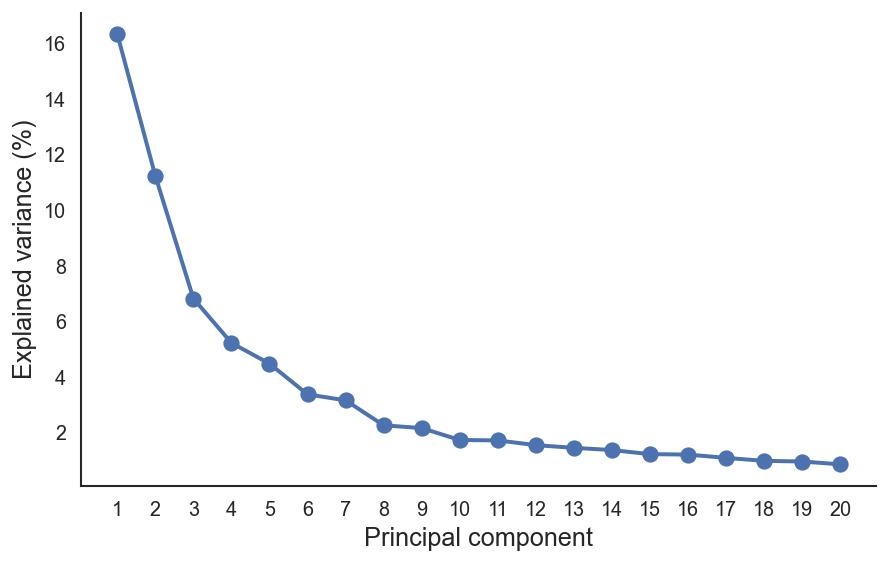

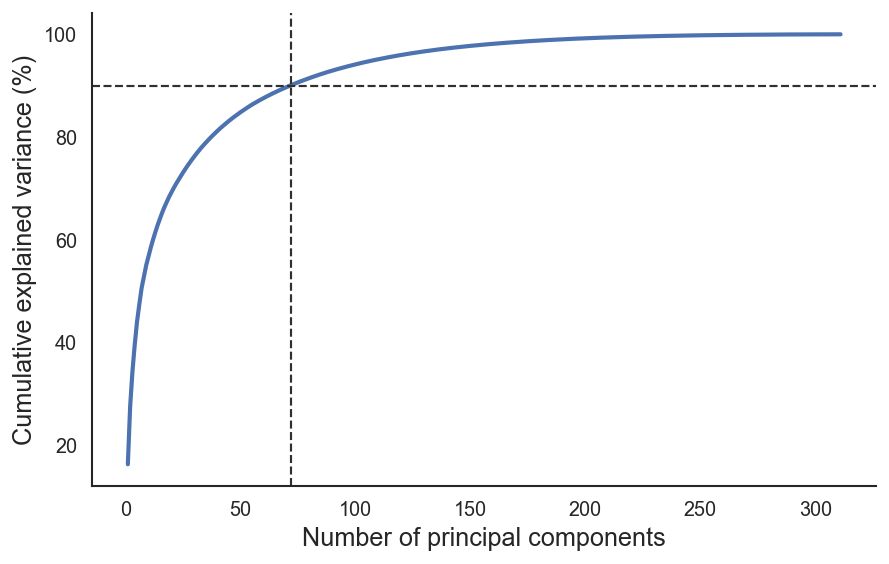

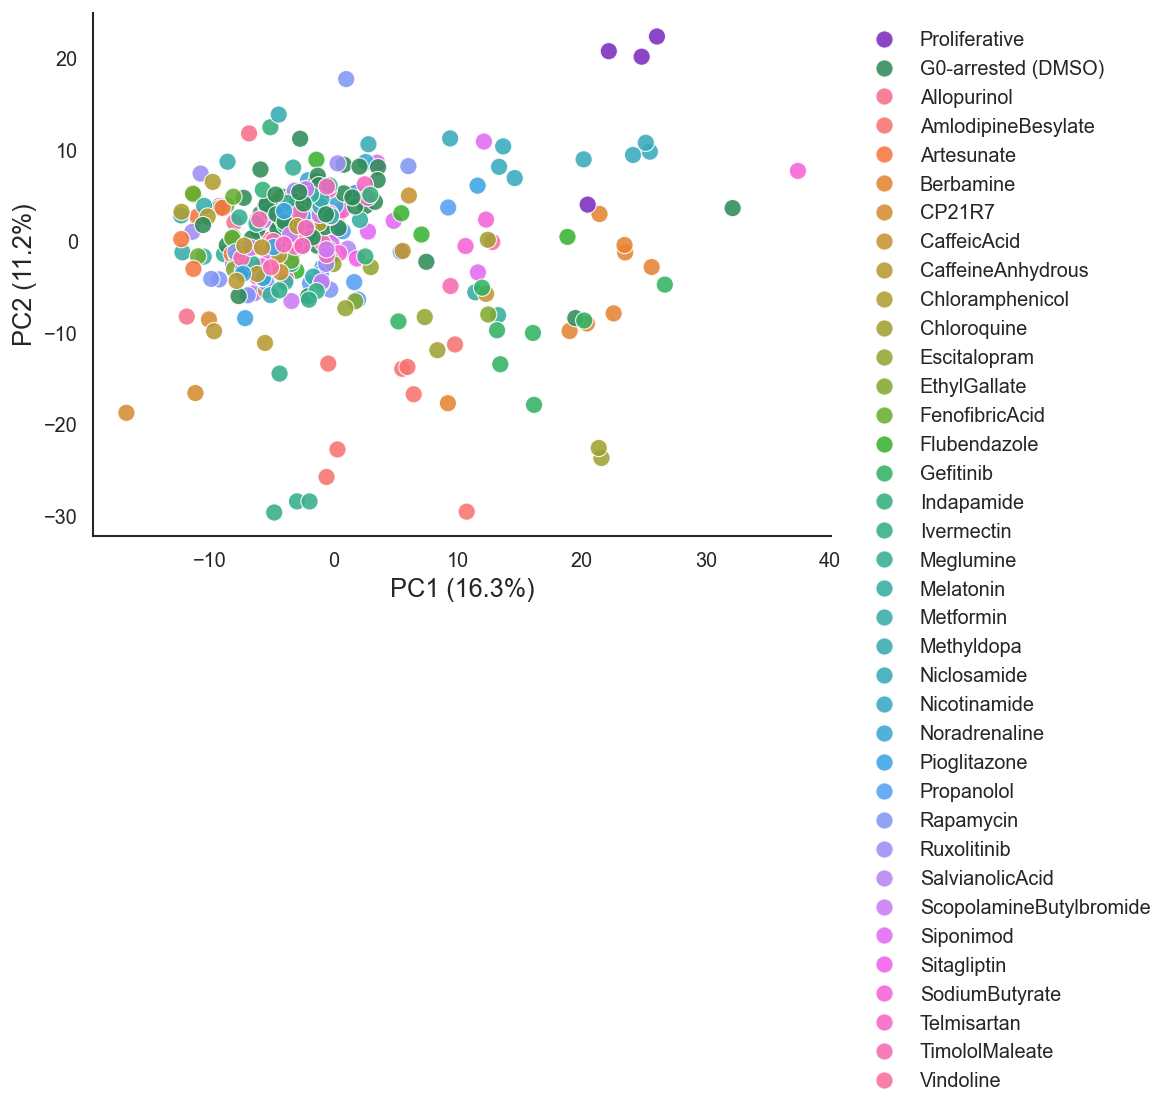

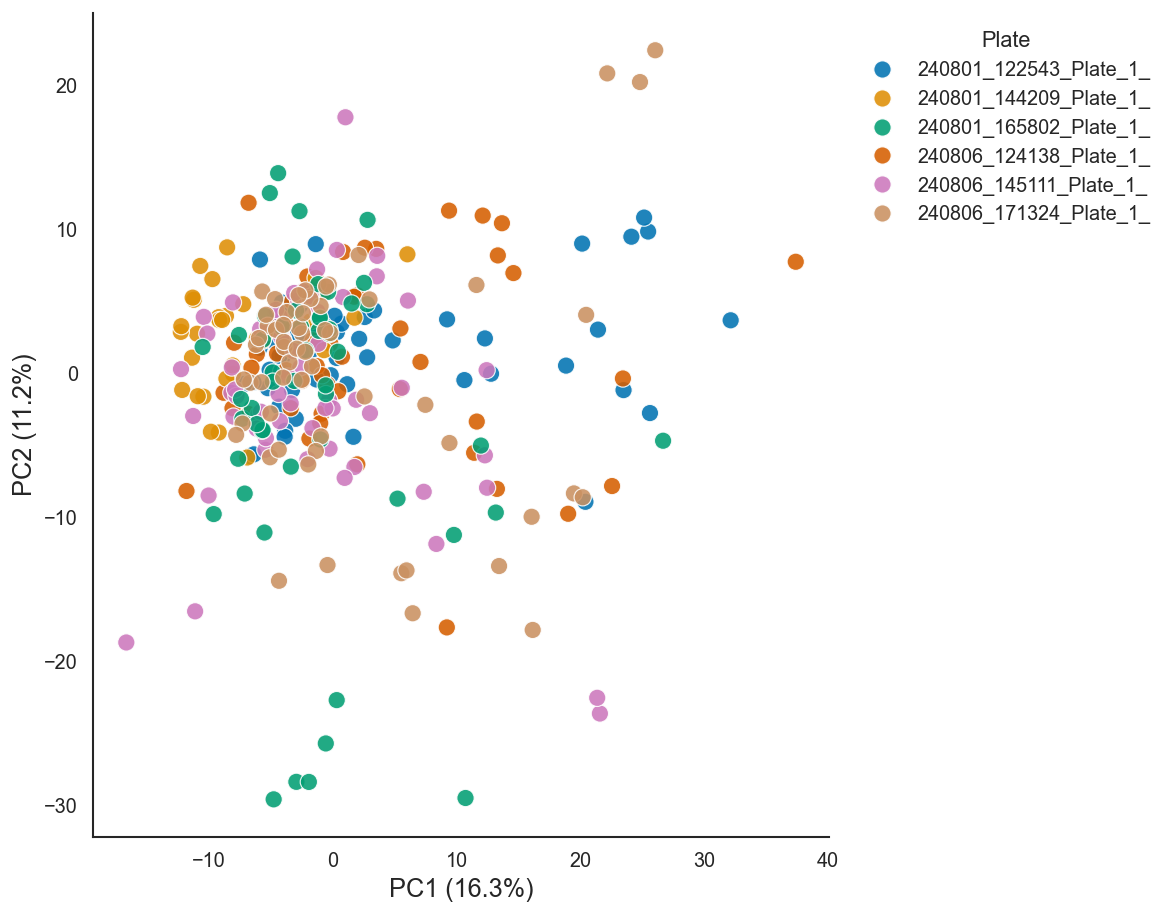

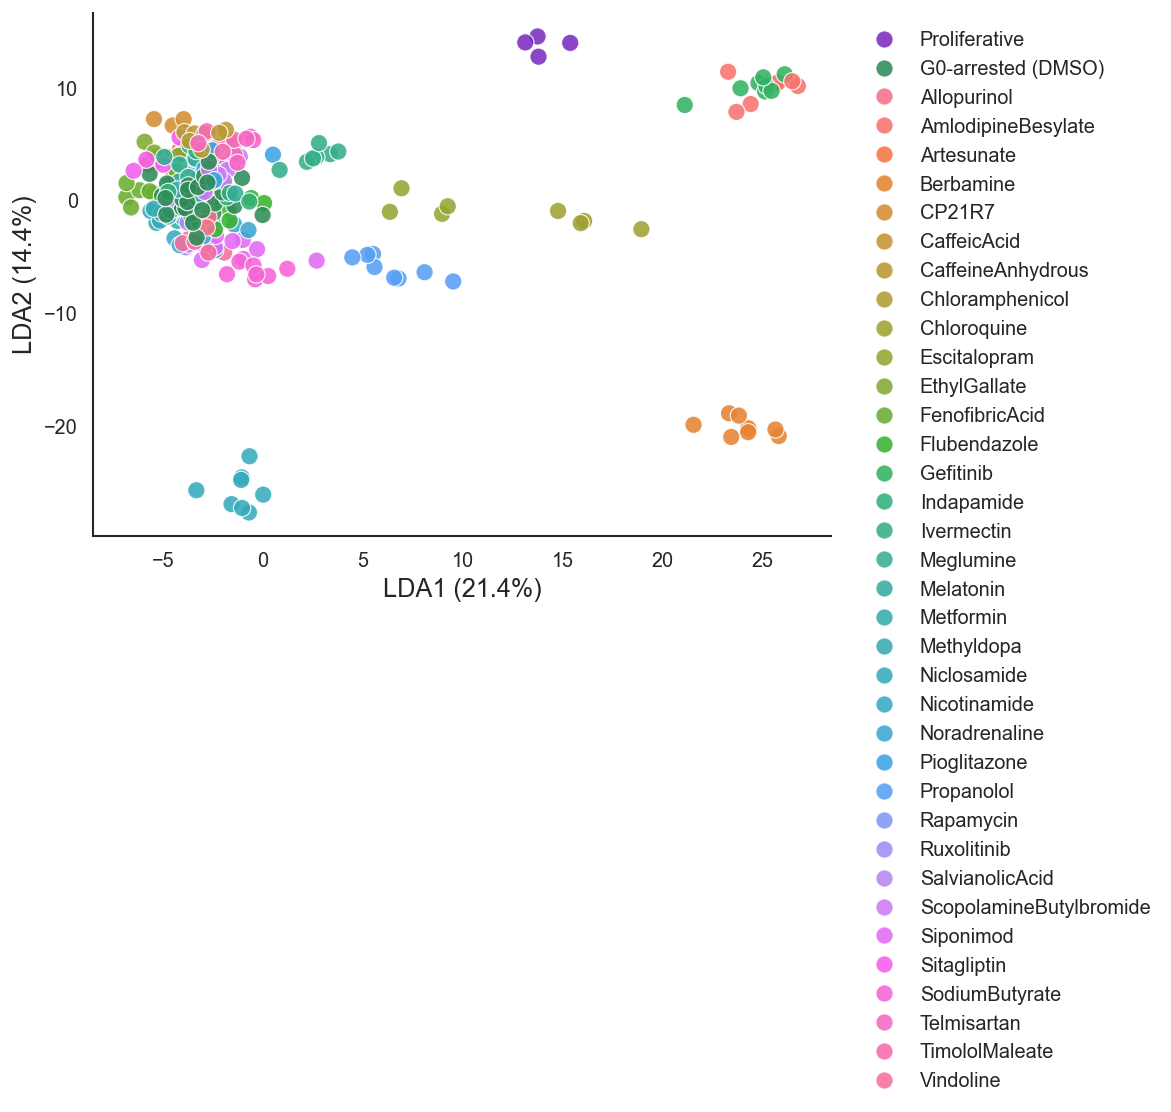

In [6]:
plot_components = min(
    20,
    max_pca_components,
)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(
    np.arange(1, plot_components + 1),
    (
        pca_full.explained_variance_ratio_[
            :plot_components
        ]
        * 100
    ),
    marker="o",
    color=PCA_COLOR,
    linewidth=2.2,
)
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance (%)")
ax.set_xticks(np.arange(1, plot_components + 1))
sns.despine()
save_figure("PCA_scree_plot.png", OUTPUT_DIR)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(
    np.arange(1, max_pca_components + 1),
    cumulative_variance * 100,
    color=PCA_COLOR,
    linewidth=2.3,
)
ax.axhline(
    PCA_VARIANCE_TARGET * 100,
    linestyle="--",
    linewidth=1.2,
    color=THRESHOLD_COLOR,
)
ax.axvline(
    n_pca_retained,
    linestyle="--",
    linewidth=1.2,
    color=THRESHOLD_COLOR,
)
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance (%)")
sns.despine()
save_figure(
    "PCA_cumulative_variance.png",
    OUTPUT_DIR,
)

fig, ax = plt.subplots(figsize=(9.2, 7.2))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue=CONDITION_COL,
    hue_order=condition_order,
    palette=condition_palette,
    s=92,
    alpha=0.88,
    edgecolor="white",
    linewidth=0.65,
    ax=ax,
)
ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)"
)
ax.legend(
    title=None,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)
sns.despine()
save_figure("PCA_by_condition.png", OUTPUT_DIR)

fig, ax = plt.subplots(figsize=(9.2, 7.2))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue=PLATE_COL,
    hue_order=plate_order,
    palette=plate_palette,
    s=92,
    alpha=0.88,
    edgecolor="white",
    linewidth=0.65,
    ax=ax,
)
ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)"
)
ax.legend(
    title="Plate",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)
sns.despine()
save_figure("PCA_by_plate.png", OUTPUT_DIR)

if lda_df is None:
    print("LDA plot skipped because no valid LDA axis was available.")
elif len(lda_columns) >= 2:
    fig, ax = plt.subplots(figsize=(9.2, 7.2))
    sns.scatterplot(
        data=lda_df,
        x="LDA1",
        y="LDA2",
        hue="Class",
        hue_order=condition_order,
        palette=condition_palette,
        s=92,
        alpha=0.88,
        edgecolor="white",
        linewidth=0.65,
        ax=ax,
    )
    ax.set_xlabel(
        f"LDA1 ({lda.explained_variance_ratio_[0] * 100:.1f}%)"
    )
    ax.set_ylabel(
        f"LDA2 ({lda.explained_variance_ratio_[1] * 100:.1f}%)"
    )
    ax.legend(
        title=None,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False,
    )
    sns.despine()
    save_figure("LDA_by_condition.png", OUTPUT_DIR)
else:
    fig, ax = plt.subplots(figsize=(8, 3.8))
    one_dimensional_lda = lda_df.sort_values("LDA1").copy()
    one_dimensional_lda["Row"] = 0

    sns.scatterplot(
        data=one_dimensional_lda,
        x="LDA1",
        y="Row",
        hue="Class",
        hue_order=condition_order,
        palette=condition_palette,
        s=92,
        alpha=0.88,
        edgecolor="white",
        linewidth=0.65,
        ax=ax,
    )
    ax.set_yticks([])
    ax.set_ylabel("")
    ax.set_xlabel(
        f"LDA1 ({lda.explained_variance_ratio_[0] * 100:.1f}%)"
    )
    ax.legend(
        title=None,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False,
    )
    sns.despine(left=True)
    save_figure("LDA1_by_condition.png", OUTPUT_DIR)

## 6.1 Static 3D PCA and LDA

The following figures use Matplotlib to generate static three-dimensional visualizations. PCA is unsupervised, whereas LDA is a supervised projection based on the treatment labels.

The figures are exported as high-resolution PNG files in `OUTPUT_DIR`, together with the corresponding coordinates in CSV format.


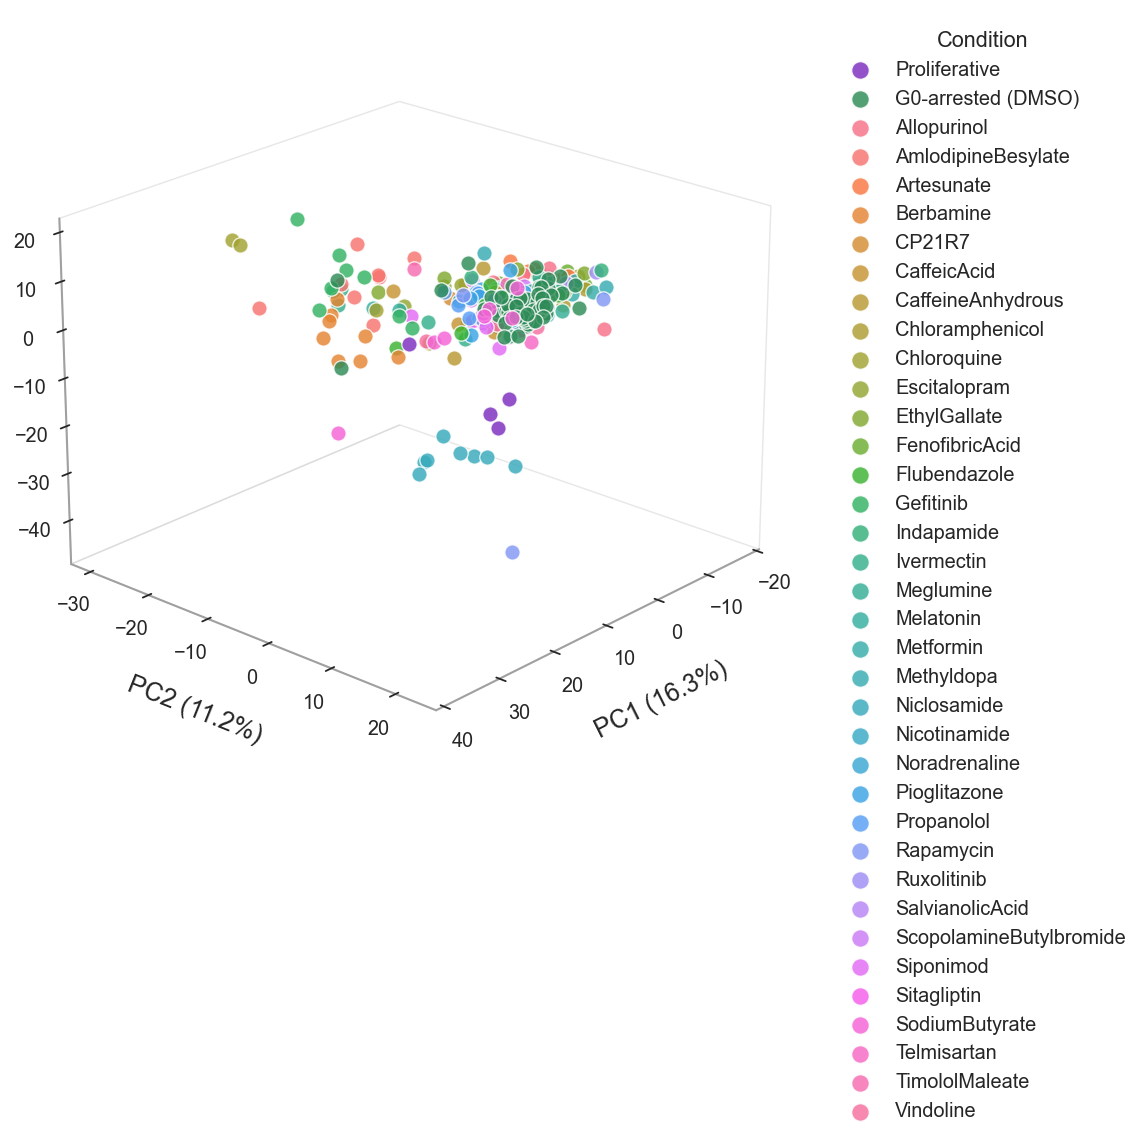

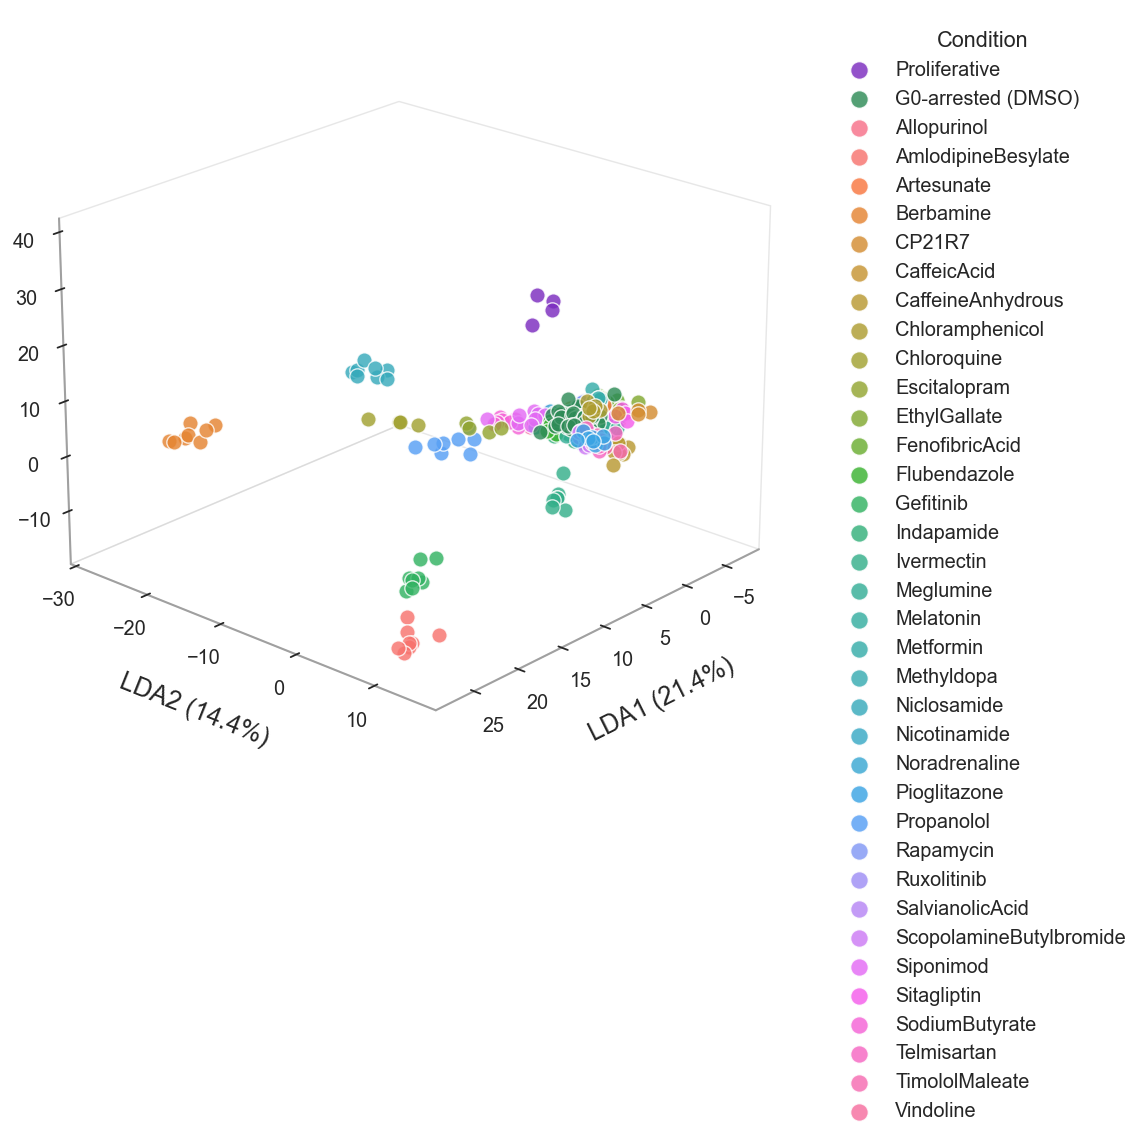

In [7]:
# Static 3D PCA and LDA using Matplotlib
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401


def format_3d_axis(ax):
    """Apply a clean publication-oriented style to a 3D axis."""
    ax.grid(False)

    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
        axis.pane.set_edgecolor("#D0D0D0")
        axis.line.set_color("#A0A0A0")

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=11,
        pad=3,
    )

    ax.xaxis.label.set_size(14)
    ax.yaxis.label.set_size(14)
    ax.zaxis.label.set_size(14)

    ax.view_init(
        elev=22,
        azim=42,
    )


# ------------------------------------------------------------
# PCA 3D
# ------------------------------------------------------------
if max_pca_components < 3:
    print(
        "PCA 3D skipped: fewer than three valid principal "
        "components are available."
    )
else:
    pca_3d = PCA(
        n_components=3,
        random_state=RANDOM_STATE,
    )

    X_pca_3d = pca_3d.fit_transform(X_scaled)

    pca_3d_df = analysis_df[
        [CONDITION_COL, PLATE_COL, "Replicate_ID"]
    ].copy()

    if (
        WELL_COL is not None
        and WELL_COL in analysis_df.columns
    ):
        pca_3d_df[WELL_COL] = analysis_df[WELL_COL].values

    pca_3d_df["PC1"] = X_pca_3d[:, 0]
    pca_3d_df["PC2"] = X_pca_3d[:, 1]
    pca_3d_df["PC3"] = X_pca_3d[:, 2]

    pca_3d_variance = (
        pca_3d.explained_variance_ratio_ * 100
    )

    fig = plt.figure(figsize=(10.2, 8.4))
    ax = fig.add_subplot(111, projection="3d")

    for condition in condition_order:
        condition_mask = (
            pca_3d_df[CONDITION_COL] == condition
        )

        condition_data = pca_3d_df.loc[condition_mask]

        if condition_data.empty:
            continue

        ax.scatter(
            condition_data["PC1"],
            condition_data["PC2"],
            condition_data["PC3"],
            s=72,
            alpha=0.82,
            color=condition_palette[condition],
            edgecolor="white",
            linewidth=0.75,
            label=condition,
            depthshade=False,
        )

    ax.set_xlabel(
        f"PC1 ({pca_3d_variance[0]:.1f}%)",
        labelpad=12,
    )
    ax.set_ylabel(
        f"PC2 ({pca_3d_variance[1]:.1f}%)",
        labelpad=12,
    )
    ax.set_zlabel(
        f"PC3 ({pca_3d_variance[2]:.1f}%)",
        labelpad=12,
    )

    format_3d_axis(ax)

    ax.legend(
        title="Condition",
        frameon=False,
        bbox_to_anchor=(1.04, 1.0),
        loc="upper left",
        fontsize=11,
        title_fontsize=12,
        markerscale=1.15,
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "PCA_3D_static.png",
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()
    plt.close(fig)

    pca_3d_df.to_csv(
        OUTPUT_DIR / "PCA_3D_coordinates.csv",
        index=False,
    )


# ------------------------------------------------------------
# LDA 3D
# ------------------------------------------------------------
max_lda_3d_components = min(
    3,
    y.nunique() - 1,
    X_scaled.shape[1],
    X_scaled.shape[0] - y.nunique(),
)

if max_lda_3d_components < 3:
    print(
        "LDA 3D skipped: only "
        f"{max_lda_3d_components} discriminant axes "
        "are mathematically available. At least four classes "
        "and sufficient observations are required."
    )
else:
    lda_3d = LinearDiscriminantAnalysis(
        n_components=3
    )

    X_lda_3d = lda_3d.fit_transform(
        X_scaled,
        y,
    )

    lda_3d_df = analysis_df[
        [CONDITION_COL, PLATE_COL, "Replicate_ID"]
    ].copy()

    if (
        WELL_COL is not None
        and WELL_COL in analysis_df.columns
    ):
        lda_3d_df[WELL_COL] = analysis_df[WELL_COL].values

    lda_3d_df["LDA1"] = X_lda_3d[:, 0]
    lda_3d_df["LDA2"] = X_lda_3d[:, 1]
    lda_3d_df["LDA3"] = X_lda_3d[:, 2]

    lda_3d_variance = (
        lda_3d.explained_variance_ratio_ * 100
    )

    fig = plt.figure(figsize=(10.2, 8.4))
    ax = fig.add_subplot(111, projection="3d")

    for condition in condition_order:
        condition_mask = (
            lda_3d_df[CONDITION_COL] == condition
        )

        condition_data = lda_3d_df.loc[condition_mask]

        if condition_data.empty:
            continue

        ax.scatter(
            condition_data["LDA1"],
            condition_data["LDA2"],
            condition_data["LDA3"],
            s=72,
            alpha=0.82,
            color=condition_palette[condition],
            edgecolor="white",
            linewidth=0.75,
            label=condition,
            depthshade=False,
        )

    ax.set_xlabel(
        f"LDA1 ({lda_3d_variance[0]:.1f}%)",
        labelpad=12,
    )
    ax.set_ylabel(
        f"LDA2 ({lda_3d_variance[1]:.1f}%)",
        labelpad=12,
    )
    ax.set_zlabel(
        f"LDA3 ({lda_3d_variance[2]:.1f}%)",
        labelpad=12,
    )

    format_3d_axis(ax)

    ax.legend(
        title="Condition",
        frameon=False,
        bbox_to_anchor=(1.04, 1.0),
        loc="upper left",
        fontsize=11,
        title_fontsize=12,
        markerscale=1.15,
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "LDA_3D_static.png",
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()
    plt.close(fig)

    lda_3d_df.to_csv(
        OUTPUT_DIR / "LDA_3D_coordinates.csv",
        index=False,
    )

## 7. PCA feature contributions

Absolute loadings are summarized by broad feature family. These results describe the variance structure and should not be interpreted as causal mechanisms.


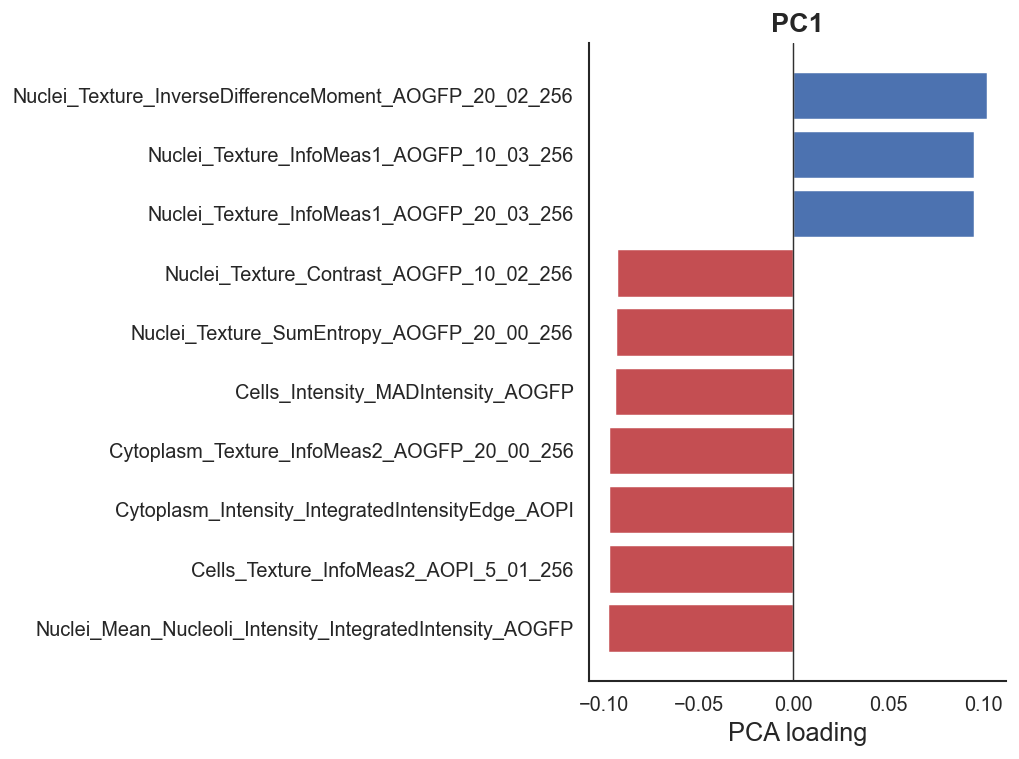

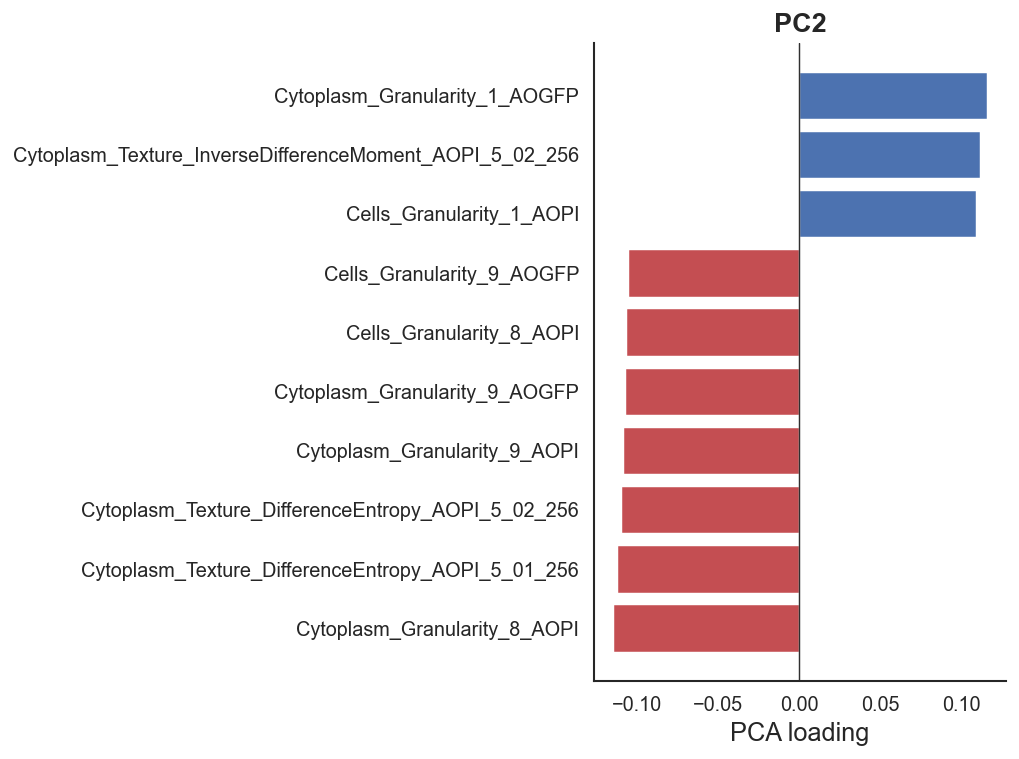

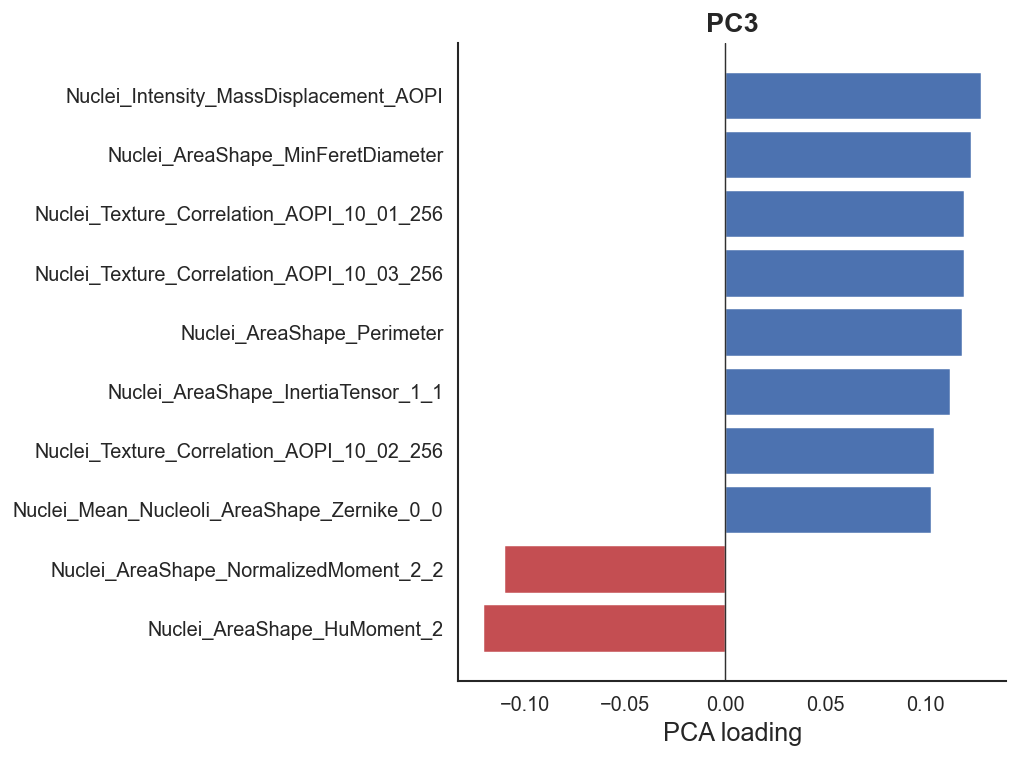

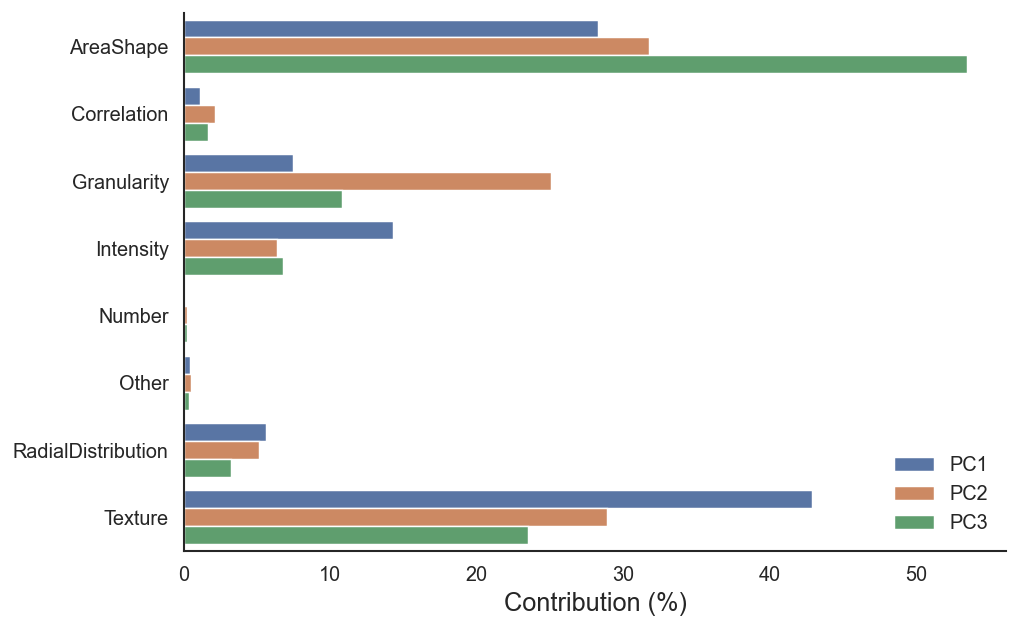

In [22]:
pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_columns,
    columns=pca_columns,
)

for component in pca_columns[:3]:
    selected_features = (
        pca_loadings[component]
        .abs()
        .nlargest(10)
        .index
    )
    selected_loadings = (
        pca_loadings
        .loc[selected_features, component]
        .sort_values()
    )

    fig, ax = plt.subplots(figsize=(8, 6))
    bar_colors = [
        PCA_COLOR if value >= 0 else "#C44E52"
        for value in selected_loadings.values
    ]
    ax.barh(
        selected_loadings.index,
        selected_loadings.values,
        color=bar_colors,
    )
    ax.axvline(
        0,
        color=THRESHOLD_COLOR,
        linewidth=0.8,
    )
    ax.set_xlabel("PCA loading")
    ax.set_ylabel("")
    ax.set_title(component)
    sns.despine()
    save_figure(
        f"Top_PCA_loadings_{component}.png",
        OUTPUT_DIR,
    )

contribution_tables = []
for component in pca_columns[:3]:
    absolute_loadings = pca_loadings[component].abs()
    total = absolute_loadings.sum()

    contribution = pd.DataFrame({
        "Feature": absolute_loadings.index,
        "Absolute loading": absolute_loadings.values,
    })
    contribution["Feature family"] = (
        contribution["Feature"].map(feature_family)
    )
    contribution = (
        contribution
        .groupby("Feature family", observed=True)[
            "Absolute loading"
        ]
        .sum()
        .div(total)
        .mul(100)
        .reset_index(name="Contribution (%)")
    )
    contribution["Component"] = component
    contribution_tables.append(contribution)

pca_family_contribution = pd.concat(
    contribution_tables,
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=pca_family_contribution,
    x="Contribution (%)",
    y="Feature family",
    hue="Component",
    palette=sns.color_palette(
        "deep",
        n_colors=min(3, len(pca_columns)),
    ),
    ax=ax,
)
ax.set_ylabel("")
ax.legend(title=None, frameon=False)
sns.despine()
save_figure(
    "PCA_feature_family_contribution.png",
    OUTPUT_DIR,
)

pca_loadings.to_csv(
    OUTPUT_DIR / "PCA_feature_loadings.csv"
)
pca_family_contribution.to_csv(
    OUTPUT_DIR / "PCA_feature_family_contribution.csv",
    index=False,
)

## 8. Biological-condition versus plate structure

Silhouette scores quantify whether the retained PCA space is organized more strongly by biological condition or by plate.


,Grouping,Silhouette score,Number of groups
0,Biological condition,-0.088446,37
1,Plate,-0.000320,6


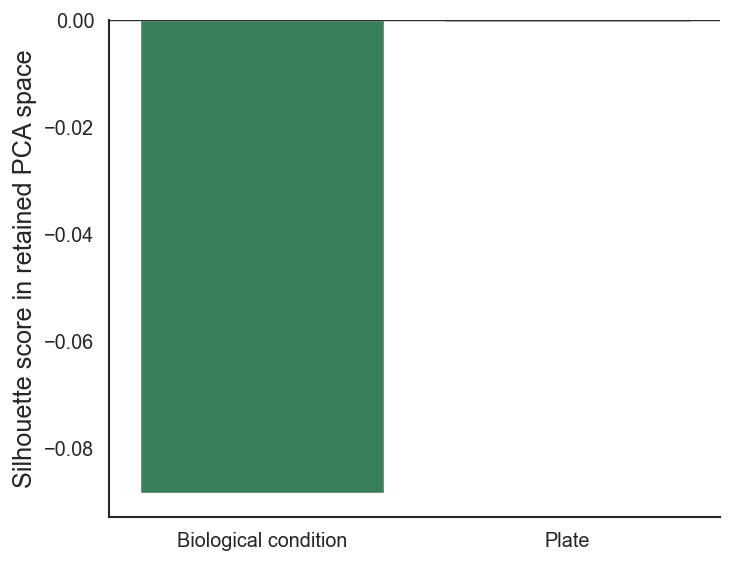

In [9]:
pca_structure_table = pd.DataFrame([
    {
        "Grouping": "Biological condition",
        "Silhouette score": safe_silhouette(
            X_pca,
            analysis_df[CONDITION_COL],
        ),
        "Number of groups": (
            analysis_df[CONDITION_COL].nunique()
        ),
    },
    {
        "Grouping": "Plate",
        "Silhouette score": safe_silhouette(
            X_pca,
            analysis_df[PLATE_COL],
        ),
        "Number of groups": (
            analysis_df[PLATE_COL].nunique()
        ),
    },
])

display(pca_structure_table)

structure_palette = {
    "Biological condition": G0_COLOR,
    "Plate": NEUTRAL_COLOR,
}

valid_structure = pca_structure_table.dropna(
    subset=["Silhouette score"]
)

if not valid_structure.empty:
    fig, ax = plt.subplots(figsize=(5.8, 4.5))
    sns.barplot(
        data=valid_structure,
        x="Grouping",
        y="Silhouette score",
        hue="Grouping",
        palette=structure_palette,
        legend=False,
        ax=ax,
    )
    ax.axhline(
        0,
        color=THRESHOLD_COLOR,
        linewidth=0.8,
    )
    ax.set_xlabel("")
    ax.set_ylabel(
        "Silhouette score in retained PCA space"
    )
    sns.despine()
    save_figure(
        "PCA_condition_vs_plate_silhouette.png",
        OUTPUT_DIR,
    )

pca_structure_table.to_csv(
    OUTPUT_DIR / "PCA_condition_vs_plate_silhouette.csv",
    index=False,
)

## 9. Data-driven K-means clustering

K is selected independently in PCA and LDA spaces using the maximum silhouette score. Because a cluster may contain profiles from more than one treatment, labels describe the **major conditions within each cluster** rather than assigning a single biological identity. Up to three conditions are displayed when each contributes at least 15% of the cluster. The largest cluster can therefore be labelled with G0-arrested together with other substantial conditions.

Best K in PCA space: 3
Best K in LDA space: 6


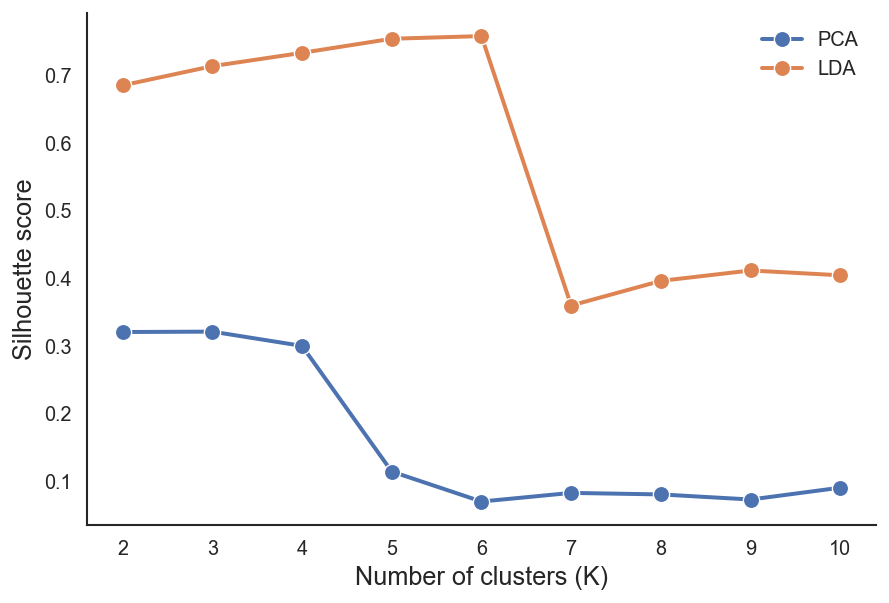

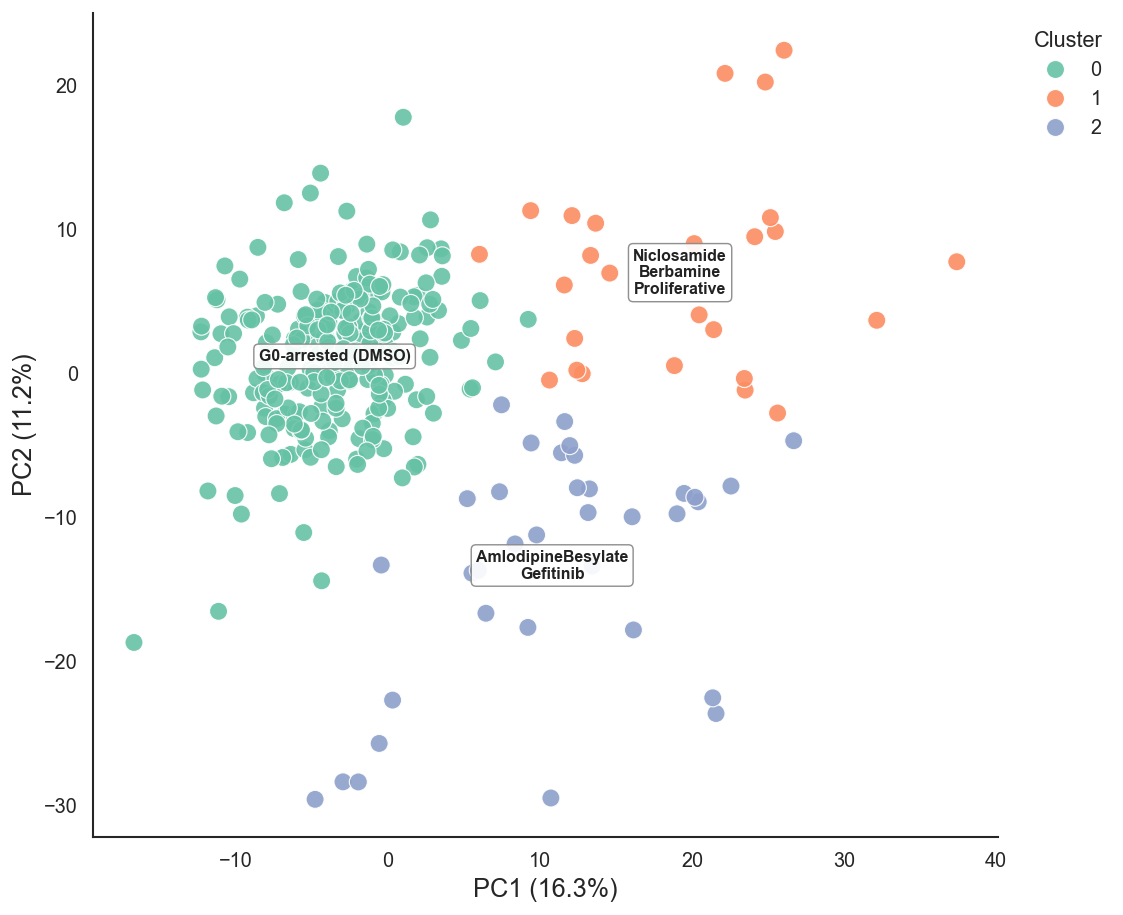

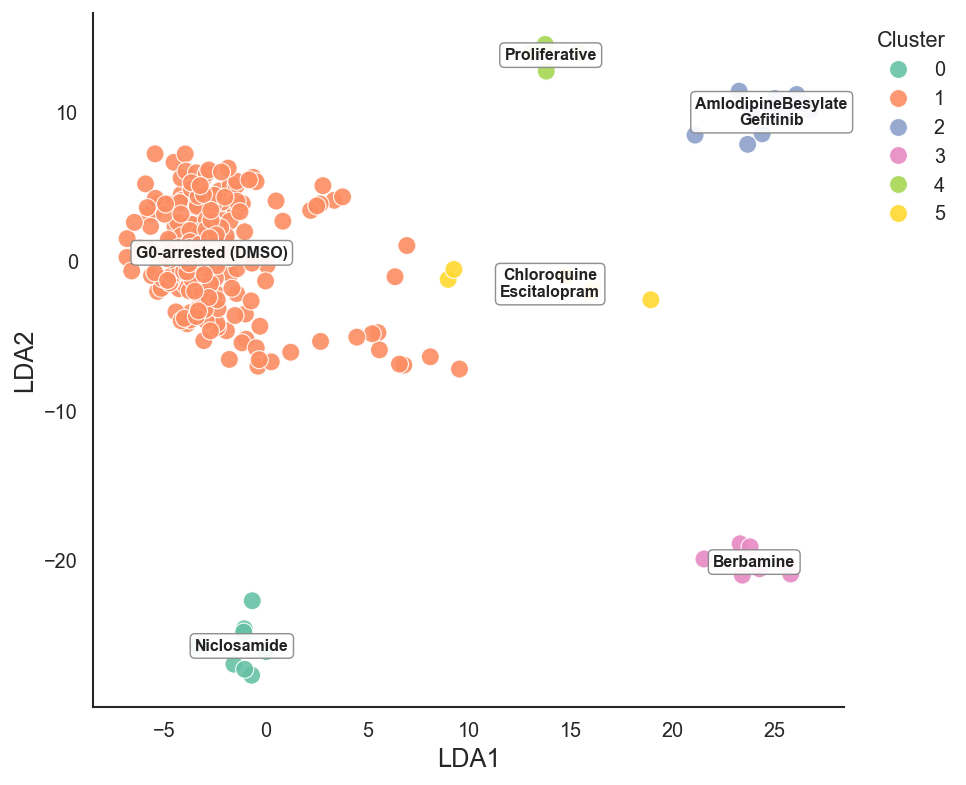

In [10]:
silhouette_pca = evaluate_kmeans(
    X_pca,
    space_name="PCA",
    min_k=MIN_K,
    max_k=MAX_K,
)

best_k_pca = int(
    silhouette_pca.loc[
        silhouette_pca["Silhouette score"].idxmax(),
        "K",
    ]
)

if X_lda is not None:
    silhouette_lda = evaluate_kmeans(
        X_lda,
        space_name="LDA",
        min_k=MIN_K,
        max_k=MAX_K,
    )
    best_k_lda = int(
        silhouette_lda.loc[
            silhouette_lda["Silhouette score"].idxmax(),
            "K",
        ]
    )
else:
    silhouette_lda = pd.DataFrame(
        columns=["Space", "K", "Silhouette score"]
    )
    best_k_lda = None

silhouette_df = pd.concat(
    [silhouette_pca, silhouette_lda],
    ignore_index=True,
)

print(f"Best K in PCA space: {best_k_pca}")
print(f"Best K in LDA space: {best_k_lda}")

fig, ax = plt.subplots(figsize=(7, 4.8))
space_palette = {
    "PCA": PCA_COLOR,
    "LDA": LDA_COLOR,
}
sns.lineplot(
    data=silhouette_df,
    x="K",
    y="Silhouette score",
    hue="Space",
    marker="o",
    palette=space_palette,
    linewidth=2.2,
    markersize=9,
    ax=ax,
)
ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Silhouette score")
ax.legend(title=None, frameon=False)
sns.despine()
save_figure(
    "Kmeans_silhouette_PCA_and_LDA.png",
    OUTPUT_DIR,
)

# PCA clusters
kmeans_pca = KMeans(
    n_clusters=best_k_pca,
    random_state=RANDOM_STATE,
    n_init=50,
)
pca_cluster_df = pca_df.copy()
pca_cluster_df["Cluster"] = (
    kmeans_pca.fit_predict(X_pca).astype(int)
)

fig, ax = plt.subplots(figsize=(8.8, 7.2))
sns.scatterplot(
    data=pca_cluster_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette=cluster_palette[:best_k_pca],
    s=100,
    alpha=0.90,
    edgecolor="white",
    linewidth=0.65,
    ax=ax,
)

(
    pca_cluster_names,
    pca_largest_cluster,
    pca_cluster_sizes,
) = annotate_clusters(
    ax=ax,
    table=pca_cluster_df,
    x_col="PC1",
    y_col="PC2",
    cluster_col="Cluster",
    condition_col=CONDITION_COL,
    min_fraction=CLUSTER_LABEL_MIN_FRACTION,
    max_labels=MAX_CLUSTER_LABELS,
)

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)"
)
ax.legend(
    title="Cluster",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)
sns.despine()
save_figure("Kmeans_clusters_PCA.png", OUTPUT_DIR)

# LDA clusters
if X_lda is not None:
    kmeans_lda = KMeans(
        n_clusters=best_k_lda,
        random_state=RANDOM_STATE,
        n_init=50,
    )
    lda_cluster_df = lda_df.copy()
    lda_cluster_df["Cluster"] = (
        kmeans_lda.fit_predict(X_lda).astype(int)
    )

    if len(lda_columns) >= 2:
        lda_x = "LDA1"
        lda_y = "LDA2"
        lda_cluster_plot_df = lda_cluster_df.copy()
    else:
        lda_x = "LDA1"
        lda_y = "_Display_y"
        lda_cluster_plot_df = lda_cluster_df.copy()
        lda_cluster_plot_df[lda_y] = 0.0

    fig, ax = plt.subplots(
        figsize=(7.6, 6.2 if len(lda_columns) >= 2 else 4.0)
    )
    sns.scatterplot(
        data=lda_cluster_plot_df,
        x=lda_x,
        y=lda_y,
        hue="Cluster",
        palette=cluster_palette[:best_k_lda],
        s=100,
        alpha=0.90,
        edgecolor="white",
        linewidth=0.65,
        ax=ax,
    )

    (
        lda_cluster_names,
        lda_largest_cluster,
        lda_cluster_sizes,
    ) = annotate_clusters(
        ax=ax,
        table=lda_cluster_plot_df,
        x_col=lda_x,
        y_col=lda_y,
        cluster_col="Cluster",
        condition_col="Class",
        min_fraction=CLUSTER_LABEL_MIN_FRACTION,
    max_labels=MAX_CLUSTER_LABELS,
    )

    ax.set_xlabel(lda_x)
    if len(lda_columns) >= 2:
        ax.set_ylabel(lda_y)
    else:
        ax.set_ylabel("")
        ax.set_yticks([])

    ax.legend(
        title="Cluster",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False,
    )
    sns.despine(
        left=(len(lda_columns) < 2)
    )
    save_figure(
        "Kmeans_clusters_LDA.png",
        OUTPUT_DIR,
    )
else:
    lda_cluster_df = None
    lda_cluster_names = {}
    lda_largest_cluster = None
    lda_cluster_sizes = pd.Series(dtype=int)
    print("LDA clustering skipped.")

### 3D visualization of K-means clusters

The PCA 3D section first identifies the G0-arrested observation farthest from the robust centre of its K-means cluster and prints its available metadata, including plate, replicate and well. When this observation is at least twice as distant as the next most isolated G0 observation, it is excluded only from the 3D display. The original data matrix, PCA, K-means assignments and downstream analyses remain unchanged.


Most isolated G0-arrested observations (review before exclusion):


,Metadata_compound,Metadata_Plate,Replicate_ID,Metadata_Well,Cluster,PC1_3D,PC2_3D,PC3_3D,Distance_to_cluster_center
2,G0-arrested (DMSO),240801_122543_Plate_1_,G0-arrested (DMSO) | 240801_122543_Plate_1_,B2,1,32.145382,3.651713,3.834472,13.448013
255,G0-arrested (DMSO),240806_171324_Plate_1_,G0-arrested (DMSO) | 240806_171324_Plate_1_,B2,2,19.478522,-8.366071,11.064998,11.561550
225,G0-arrested (DMSO),240801_165802_Plate_1_,G0-arrested (DMSO) | 240801_165802_Plate_1_,E10,0,-7.650374,-5.959623,-6.120005,11.122053
177,G0-arrested (DMSO),240806_145111_Plate_1_,G0-arrested (DMSO) | 240806_145111_Plate_1_,E7,0,3.585820,8.124694,3.915227,9.940392
251,G0-arrested (DMSO),240801_165802_Plate_1_,G0-arrested (DMSO) | 240801_165802_Plate_1_,G8,0,-2.693784,11.228631,3.594226,9.930002
147,G0-arrested (DMSO),240806_145111_Plate_1_,G0-arrested (DMSO) | 240806_145111_Plate_1_,B7,0,-2.046208,-5.989061,6.115960,9.635346
257,G0-arrested (DMSO),240806_171324_Plate_1_,G0-arrested (DMSO) | 240806_171324_Plate_1_,B4,2,7.475479,-2.216454,6.301919,9.340508
188,G0-arrested (DMSO),240806_145111_Plate_1_,G0-arrested (DMSO) | 240806_145111_Plate_1_,F8,0,3.551369,6.704162,-1.367550,8.656536
298,G0-arrested (DMSO),240806_171324_Plate_1_,G0-arrested (DMSO) | 240806_171324_Plate_1_,F6,0,2.088909,8.184121,1.753700,8.449374
22,G0-arrested (DMSO),240801_122543_Plate_1_,G0-arrested (DMSO) | 240801_122543_Plate_1_,D2,0,-5.889139,7.869059,5.520856,8.253936


No point was excluded automatically because the largest G0 distance was not at least twice the second-largest distance.


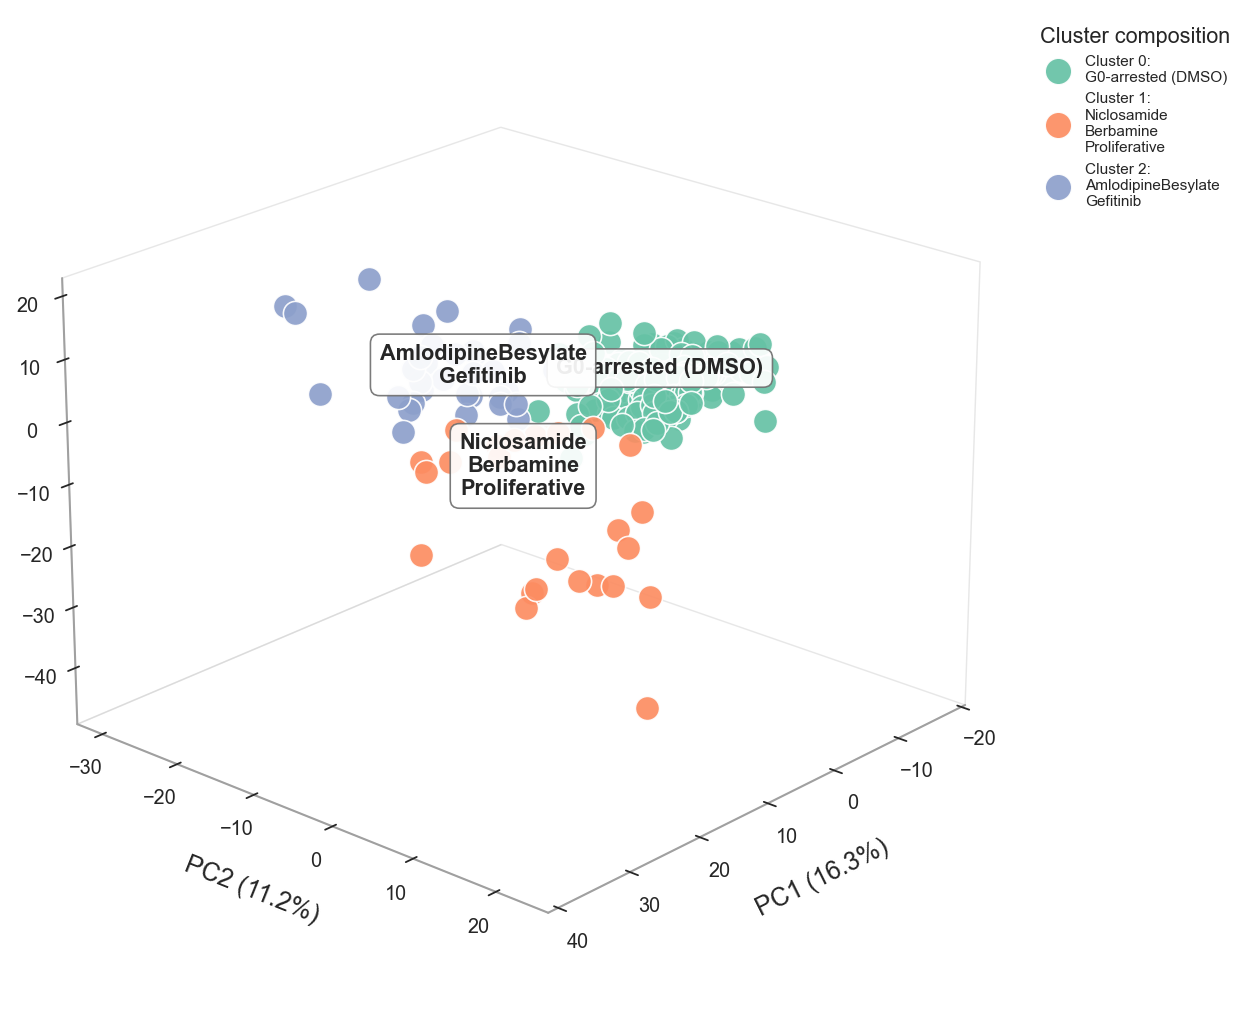

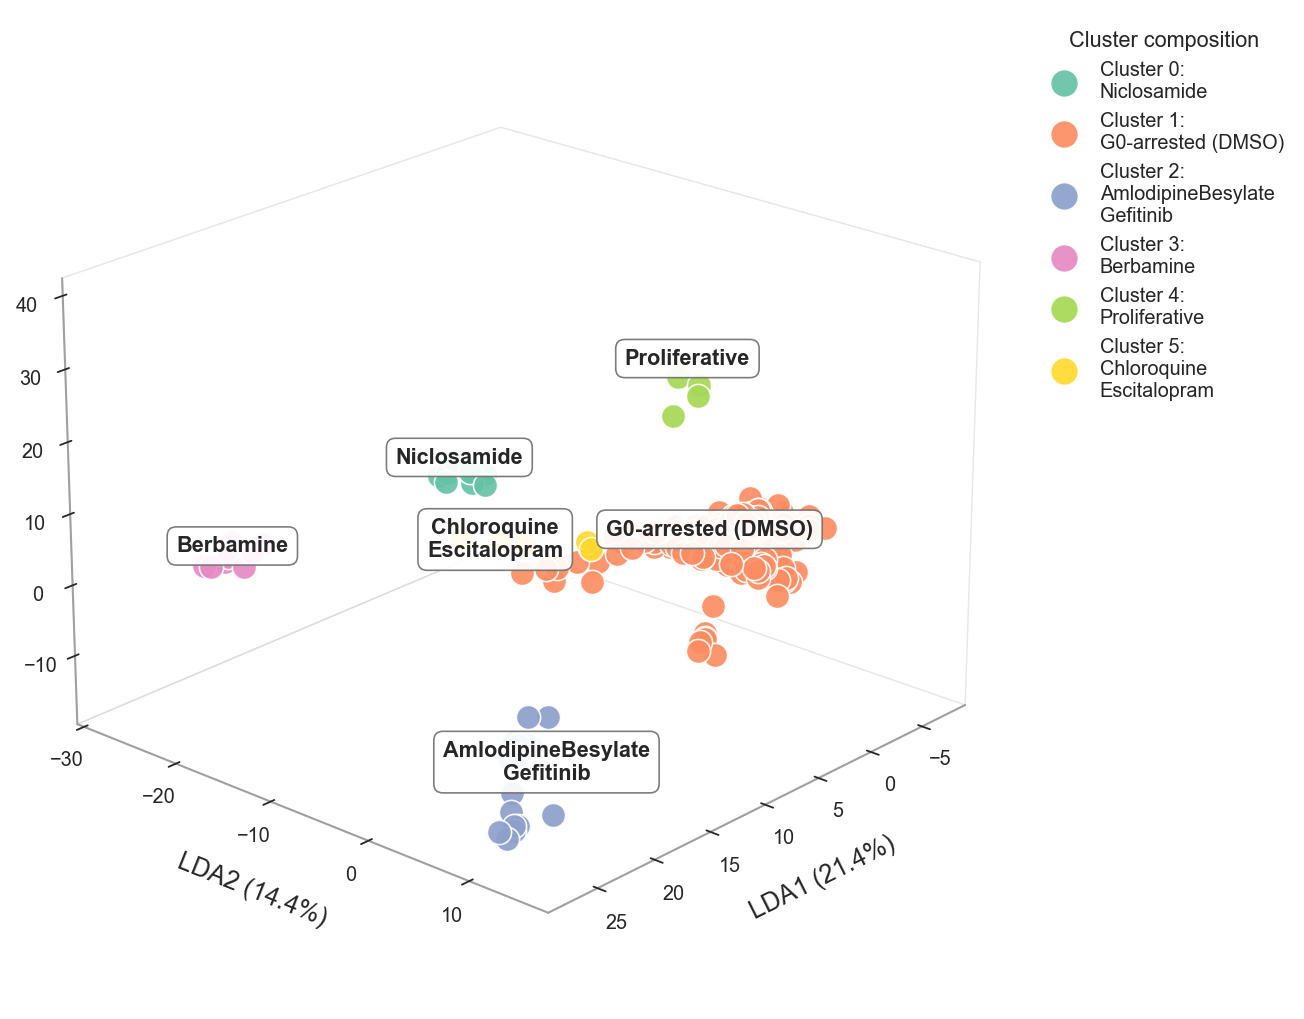

In [23]:
# Static 3D visualization of K-means clusters with compound names


def format_cluster_label(cluster_id, cluster_names):
    """Return cluster number plus the major compounds in that cluster."""
    information = cluster_names.get(cluster_id, {})
    compound_label = information.get("label", "").strip()

    if compound_label:
        return f"Cluster {cluster_id}:\n{compound_label}"

    return f"Cluster {cluster_id}"


def annotate_cluster_centroids_3d(
    ax,
    table,
    x_col,
    y_col,
    z_col,
    cluster_col,
    cluster_names,
):
    """Annotate cluster centroids without repeating identical labels."""
    candidates = []

    for cluster_id in sorted(
        table[cluster_col].astype(int).unique()
    ):
        subset = table.loc[
            table[cluster_col].astype(int) == cluster_id
        ]

        if subset.empty:
            continue

        information = cluster_names.get(cluster_id, {})
        compound_label = information.get("label", "").strip()

        if not compound_label:
            compound_label = f"Cluster {cluster_id}"

        candidates.append({
            "cluster_id": cluster_id,
            "label": compound_label,
            "size": len(subset),
            "x": subset[x_col].median(),
            "y": subset[y_col].median(),
            "z": subset[z_col].median(),
        })

    # For duplicated labels, keep only the largest corresponding cluster.
    selected = {}

    for item in candidates:
        label = item["label"]

        if (
            label not in selected
            or item["size"] > selected[label]["size"]
        ):
            selected[label] = item

    # Small deterministic offsets reduce overlap with the point cloud.
    offsets = [
        (0.0, 0.0, 3.0),
        (1.5, -1.0, 2.5),
        (-1.5, 1.0, 2.5),
        (1.0, 1.5, 3.0),
        (-1.0, -1.5, 3.0),
        (2.0, 0.5, 2.0),
    ]

    for index, item in enumerate(selected.values()):
        dx, dy, dz = offsets[index % len(offsets)]

        ax.text(
            item["x"] + dx,
            item["y"] + dy,
            item["z"] + dz,
            item["label"],
            fontsize=12.0,
            fontweight="bold",
            ha="center",
            va="center",
            bbox={
                "boxstyle": "round,pad=0.42",
                "facecolor": "white",
                "edgecolor": "#707070",
                "linewidth": 0.9,
                "alpha": 0.92,
            },
            zorder=10,
        )


# ------------------------------------------------------------
# PCA K-means clusters in 3D PCA space
# ------------------------------------------------------------
if "pca_cluster_df" not in globals():
    raise NameError(
        "pca_cluster_df was not found. Run the K-means clustering "
        "cell immediately above before running this cell."
    )

if "pca_cluster_names" not in globals():
    raise NameError(
        "pca_cluster_names was not found. Run the 2D PCA "
        "cluster-annotation cell first."
    )

if "Cluster" not in pca_cluster_df.columns:
    raise KeyError(
        "The column 'Cluster' was not found in pca_cluster_df."
    )

if len(pca_cluster_df) != X_scaled.shape[0]:
    raise ValueError(
        "pca_cluster_df and X_scaled contain different numbers "
        "of observations."
    )


if "X_pca_3d" in globals():
    X_pca_clusters_3d = X_pca_3d
    cluster_pca_variance = pca_3d_variance

else:
    pca_clusters_3d = PCA(
        n_components=3,
        random_state=RANDOM_STATE,
    )

    X_pca_clusters_3d = pca_clusters_3d.fit_transform(
        X_scaled
    )

    cluster_pca_variance = (
        pca_clusters_3d.explained_variance_ratio_ * 100
    )


pca_cluster_3d_df = pca_cluster_df.copy()

pca_cluster_3d_df["PC1_3D"] = X_pca_clusters_3d[:, 0]
pca_cluster_3d_df["PC2_3D"] = X_pca_clusters_3d[:, 1]
pca_cluster_3d_df["PC3_3D"] = X_pca_clusters_3d[:, 2]


# ------------------------------------------------------------
# Diagnose the isolated G0-arrested point
# ------------------------------------------------------------
# This does not alter the original analysis or K-means assignments.
# It identifies the observation farthest from the robust centre of its
# own K-means cluster and excludes it only from the 3D display when it
# is both G0-arrested and clearly isolated.

coordinate_cols_3d = [
    "PC1_3D",
    "PC2_3D",
    "PC3_3D",
]

pca_cluster_3d_df[
    "Distance_to_cluster_center"
] = np.nan

pca_cluster_3d_df[
    "Exclude_from_3D"
] = False


for cluster_id, cluster_subset in pca_cluster_3d_df.groupby(
    "Cluster",
    observed=True,
):
    cluster_coordinates = cluster_subset[
        coordinate_cols_3d
    ].to_numpy(dtype=float)

    robust_center = np.median(
        cluster_coordinates,
        axis=0,
    )

    distances = np.linalg.norm(
        cluster_coordinates - robust_center,
        axis=1,
    )

    pca_cluster_3d_df.loc[
        cluster_subset.index,
        "Distance_to_cluster_center",
    ] = distances


# Identify the most isolated G0-arrested observation.
g0_mask_3d = (
    pca_cluster_3d_df[CONDITION_COL]
    .astype(str)
    .str.contains(
        "G0-arrested",
        case=False,
        regex=False,
        na=False,
    )
)

g0_diagnostic = (
    pca_cluster_3d_df.loc[g0_mask_3d]
    .sort_values(
        "Distance_to_cluster_center",
        ascending=False,
    )
    .copy()
)

metadata_columns_3d = [
    column
    for column in [
        CONDITION_COL,
        PLATE_COL,
        "Replicate_ID",
        WELL_COL,
        "Cluster",
        "PC1_3D",
        "PC2_3D",
        "PC3_3D",
        "Distance_to_cluster_center",
    ]
    if column is not None
    and column in g0_diagnostic.columns
]

print(
    "Most isolated G0-arrested observations "
    "(review before exclusion):"
)

display(
    g0_diagnostic[
        metadata_columns_3d
    ].head(10)
)


# Exclude only the single most isolated G0 point when it is separated
# from the remaining G0 observations by a strong distance gap.
excluded_point_3d = pd.DataFrame()

if len(g0_diagnostic) >= 2:
    largest_distance = float(
        g0_diagnostic.iloc[0][
            "Distance_to_cluster_center"
        ]
    )

    second_distance = float(
        g0_diagnostic.iloc[1][
            "Distance_to_cluster_center"
        ]
    )

    distance_ratio = (
        largest_distance / second_distance
        if second_distance > 0
        else np.inf
    )

    # A ratio >= 2 means the candidate is at least twice as distant
    # as the next most isolated G0 observation.
    if distance_ratio >= 2.0:
        excluded_index = g0_diagnostic.index[0]

        pca_cluster_3d_df.loc[
            excluded_index,
            "Exclude_from_3D",
        ] = True

        excluded_point_3d = pca_cluster_3d_df.loc[
            [excluded_index],
            metadata_columns_3d
            + ["Exclude_from_3D"],
        ].copy()

        print(
            "Excluded from the 3D display because it is the "
            f"most isolated G0 point "
            f"(distance ratio = {distance_ratio:.2f})."
        )

        display(excluded_point_3d)

    else:
        print(
            "No point was excluded automatically because the "
            "largest G0 distance was not at least twice the "
            "second-largest distance."
        )

else:
    print(
        "Automatic exclusion was skipped because fewer than "
        "two G0-arrested observations were available."
    )


# Export the full diagnostic table and the excluded observation.
g0_diagnostic[
    metadata_columns_3d
].to_csv(
    OUTPUT_DIR / "G0_isolated_point_diagnostic.csv",
    index=False,
)

excluded_point_3d.to_csv(
    OUTPUT_DIR / "G0_point_excluded_from_3D.csv",
    index=False,
)


pca_cluster_3d_plot_df = pca_cluster_3d_df.loc[
    ~pca_cluster_3d_df["Exclude_from_3D"]
].copy()

pca_cluster_ids = sorted(
    pca_cluster_3d_plot_df[
        "Cluster"
    ].astype(int).unique()
)

pca_cluster_colors_3d = sns.color_palette(
    "Set2",
    n_colors=len(pca_cluster_ids),
)

pca_cluster_color_map_3d = dict(
    zip(
        pca_cluster_ids,
        pca_cluster_colors_3d,
    )
)


fig = plt.figure(figsize=(10.5, 8.0))
ax = fig.add_subplot(
    111,
    projection="3d",
)


for cluster_id in pca_cluster_ids:
    cluster_subset = pca_cluster_3d_plot_df.loc[
        pca_cluster_3d_plot_df[
            "Cluster"
        ].astype(int) == cluster_id
    ]

    ax.scatter(
        cluster_subset["PC1_3D"],
        cluster_subset["PC2_3D"],
        cluster_subset["PC3_3D"],
        s=180,
        alpha=0.92,
        color=pca_cluster_color_map_3d[
            cluster_id
        ],
        edgecolor="white",
        linewidth=0.90,
        label=format_cluster_label(
            cluster_id,
            pca_cluster_names,
        ),
        depthshade=False,
    )


annotate_cluster_centroids_3d(
    ax=ax,
    table=pca_cluster_3d_plot_df,
    x_col="PC1_3D",
    y_col="PC2_3D",
    z_col="PC3_3D",
    cluster_col="Cluster",
    cluster_names=pca_cluster_names,
)


ax.set_xlabel(
    f"PC1 ({cluster_pca_variance[0]:.1f}%)",
    labelpad=12,
)

ax.set_ylabel(
    f"PC2 ({cluster_pca_variance[1]:.1f}%)",
    labelpad=12,
)

ax.set_zlabel(
    f"PC3 ({cluster_pca_variance[2]:.1f}%)",
    labelpad=12,
)

format_3d_axis(ax)

ax.legend(
    title="Cluster composition",
    frameon=False,
    bbox_to_anchor=(1.02, 1.0),
    loc="upper left",
    fontsize=8.5,
    title_fontsize=12.0,
    markerscale=1.1,
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "Kmeans_clusters_PCA_3D_isolated_G0_excluded.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)


pca_cluster_3d_df.to_csv(
    OUTPUT_DIR
    / "Kmeans_clusters_PCA_3D_coordinates_with_diagnostic.csv",
    index=False,
)


# ------------------------------------------------------------
# LDA K-means clusters in 3D LDA space
# ------------------------------------------------------------
if (
    "lda_cluster_df" not in globals()
    or lda_cluster_df is None
):
    print(
        "LDA cluster 3D plot skipped because LDA clustering "
        "was not available."
    )

elif "lda_cluster_names" not in globals():
    print(
        "LDA cluster 3D plot skipped because lda_cluster_names "
        "was not available."
    )

elif "Cluster" not in lda_cluster_df.columns:
    print(
        "LDA cluster 3D plot skipped because the 'Cluster' "
        "column was not found in lda_cluster_df."
    )

elif "X_lda_3d" not in globals():
    print(
        "LDA cluster 3D plot skipped because three LDA axes "
        "were not available."
    )

else:
    if len(lda_cluster_df) != X_lda_3d.shape[0]:
        raise ValueError(
            "lda_cluster_df and X_lda_3d contain different "
            "numbers of observations."
        )

    lda_cluster_3d_df = lda_cluster_df.copy()

    lda_cluster_3d_df[
        "LDA1_3D"
    ] = X_lda_3d[:, 0]

    lda_cluster_3d_df[
        "LDA2_3D"
    ] = X_lda_3d[:, 1]

    lda_cluster_3d_df[
        "LDA3_3D"
    ] = X_lda_3d[:, 2]

    lda_cluster_ids = sorted(
        lda_cluster_3d_df[
            "Cluster"
        ].astype(int).unique()
    )

    lda_cluster_colors_3d = sns.color_palette(
        "Set2",
        n_colors=len(lda_cluster_ids),
    )

    lda_cluster_color_map_3d = dict(
        zip(
            lda_cluster_ids,
            lda_cluster_colors_3d,
        )
    )

    fig = plt.figure(
        figsize=(10.5, 8.0)
    )

    ax = fig.add_subplot(
        111,
        projection="3d",
    )

    for cluster_id in lda_cluster_ids:
        cluster_subset = lda_cluster_3d_df.loc[
            lda_cluster_3d_df[
                "Cluster"
            ].astype(int) == cluster_id
        ]

        ax.scatter(
            cluster_subset["LDA1_3D"],
            cluster_subset["LDA2_3D"],
            cluster_subset["LDA3_3D"],
            s=180,
            alpha=0.92,
            color=lda_cluster_color_map_3d[
                cluster_id
            ],
            edgecolor="white",
            linewidth=0.90,
            label=format_cluster_label(
                cluster_id,
                lda_cluster_names,
            ),
            depthshade=False,
        )

    annotate_cluster_centroids_3d(
        ax=ax,
        table=lda_cluster_3d_df,
        x_col="LDA1_3D",
        y_col="LDA2_3D",
        z_col="LDA3_3D",
        cluster_col="Cluster",
        cluster_names=lda_cluster_names,
    )

    if "lda_3d_variance" in globals():
        ax.set_xlabel(
            f"LDA1 ({lda_3d_variance[0]:.1f}%)",
            labelpad=12,
        )

        ax.set_ylabel(
            f"LDA2 ({lda_3d_variance[1]:.1f}%)",
            labelpad=12,
        )

        ax.set_zlabel(
            f"LDA3 ({lda_3d_variance[2]:.1f}%)",
            labelpad=12,
        )

    else:
        ax.set_xlabel(
            "LDA1",
            labelpad=8,
        )

        ax.set_ylabel(
            "LDA2",
            labelpad=8,
        )

        ax.set_zlabel(
            "LDA3",
            labelpad=8,
        )

    format_3d_axis(ax)

    ax.legend(
        title="Cluster composition",
        frameon=False,
        bbox_to_anchor=(1.02, 1.0),
        loc="upper left",
        fontsize=11,
        title_fontsize=12,
        markerscale=1.15,
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR
        / "Kmeans_clusters_LDA_3D_compound_names.png",
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()
    plt.close(fig)

    lda_cluster_3d_df.to_csv(
        OUTPUT_DIR
        / "Kmeans_clusters_LDA_3D_coordinates_compound_names.csv",
        index=False,
    )

## 10. Cluster composition and exported labels

In [12]:
def cluster_composition_table(
    table,
    cluster_col,
    condition_col,
    space_name,
    largest_cluster,
    assigned_labels,
):
    composition = (
        table
        .groupby(
            [cluster_col, condition_col],
            observed=True,
        )
        .size()
        .rename("Count")
        .reset_index()
    )

    totals = (
        composition
        .groupby(cluster_col, observed=True)["Count"]
        .transform("sum")
    )
    composition["Fraction"] = (
        composition["Count"] / totals
    )
    composition["Space"] = space_name
    composition["Largest cluster"] = (
        composition[cluster_col] == largest_cluster
    )
    composition["Displayed label"] = (
        composition[cluster_col].map({
            cluster_id: information["label"]
            for cluster_id, information
            in assigned_labels.items()
        })
    )
    composition["Included in displayed label"] = composition.apply(
        lambda row: (
            row[condition_col]
            in assigned_labels.get(
                row[cluster_col],
                {},
            ).get("conditions", [])
        ),
        axis=1,
    )

    return composition


pca_composition = cluster_composition_table(
    table=pca_cluster_df,
    cluster_col="Cluster",
    condition_col=CONDITION_COL,
    space_name="PCA",
    largest_cluster=pca_largest_cluster,
    assigned_labels=pca_cluster_names,
)

composition_tables = [pca_composition]

if lda_cluster_df is not None:
    lda_composition = cluster_composition_table(
        table=lda_cluster_df,
        cluster_col="Cluster",
        condition_col="Class",
        space_name="LDA",
        largest_cluster=lda_largest_cluster,
        assigned_labels=lda_cluster_names,
    )
    composition_tables.append(lda_composition)

cluster_composition = pd.concat(
    composition_tables,
    ignore_index=True,
)

display(cluster_composition)

silhouette_df.to_csv(
    OUTPUT_DIR / "Kmeans_silhouette_scores.csv",
    index=False,
)
pca_cluster_df.to_csv(
    OUTPUT_DIR / "PCA_cluster_assignments.csv",
    index=False,
)
if lda_cluster_df is not None:
    lda_cluster_df.to_csv(
        OUTPUT_DIR / "LDA_cluster_assignments.csv",
        index=False,
    )
cluster_composition.to_csv(
    OUTPUT_DIR / "Kmeans_cluster_composition_and_labels.csv",
    index=False,
)

,Cluster,Metadata_compound,Count,Fraction,Space,Largest cluster,Displayed label,Included in displayed label,Class
0,0,Allopurinol,8,0.031873,PCA,True,G0-arrested (DMSO),False,NaN
1,0,Artesunate,7,0.027888,PCA,True,G0-arrested (DMSO),False,NaN
2,0,CP21R7,4,0.015936,PCA,True,G0-arrested (DMSO),False,NaN
3,0,CaffeicAcid,3,0.011952,PCA,True,G0-arrested (DMSO),False,NaN
4,0,CaffeineAnhydrous,8,0.031873,PCA,True,G0-arrested (DMSO),False,NaN
...,...,...,...,...,...,...,...,...,...
87,2,NaN,8,0.500000,LDA,False,AmlodipineBesylate\nGefitinib,True,Gefitinib
88,3,NaN,8,1.000000,LDA,False,Berbamine,True,Berbamine
89,4,NaN,4,1.000000,LDA,False,Proliferative,True,Proliferative
90,5,NaN,4,0.666667,LDA,False,Chloroquine\nEscitalopram,True,Chloroquine


## 11. LDA feature contributions

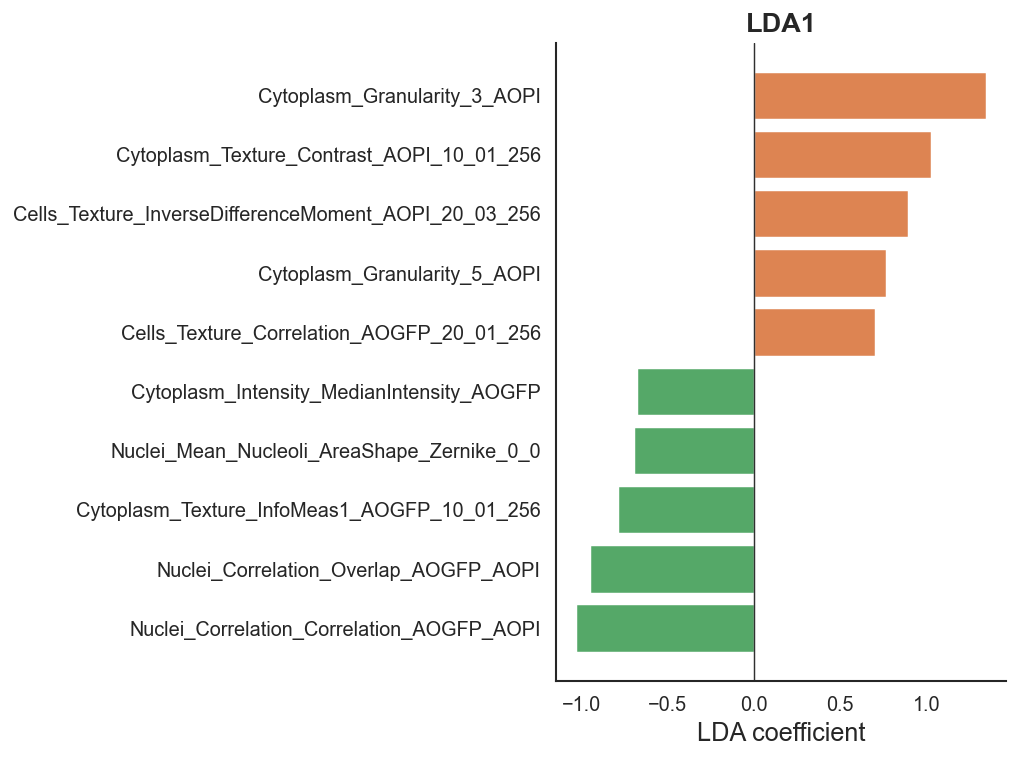

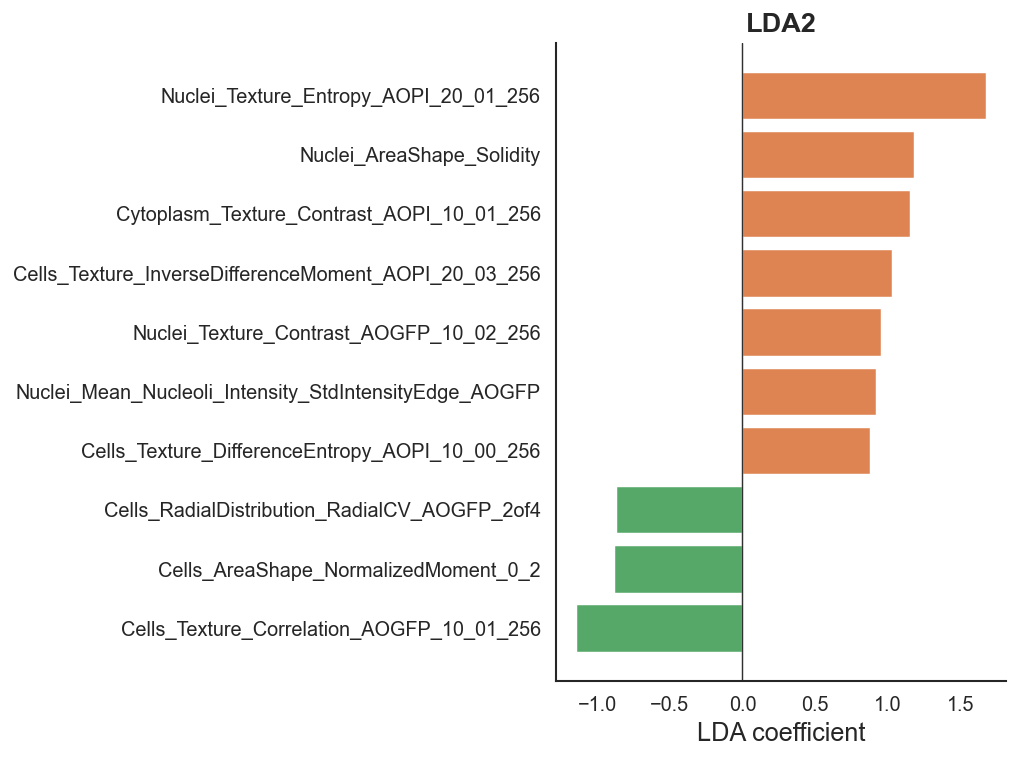

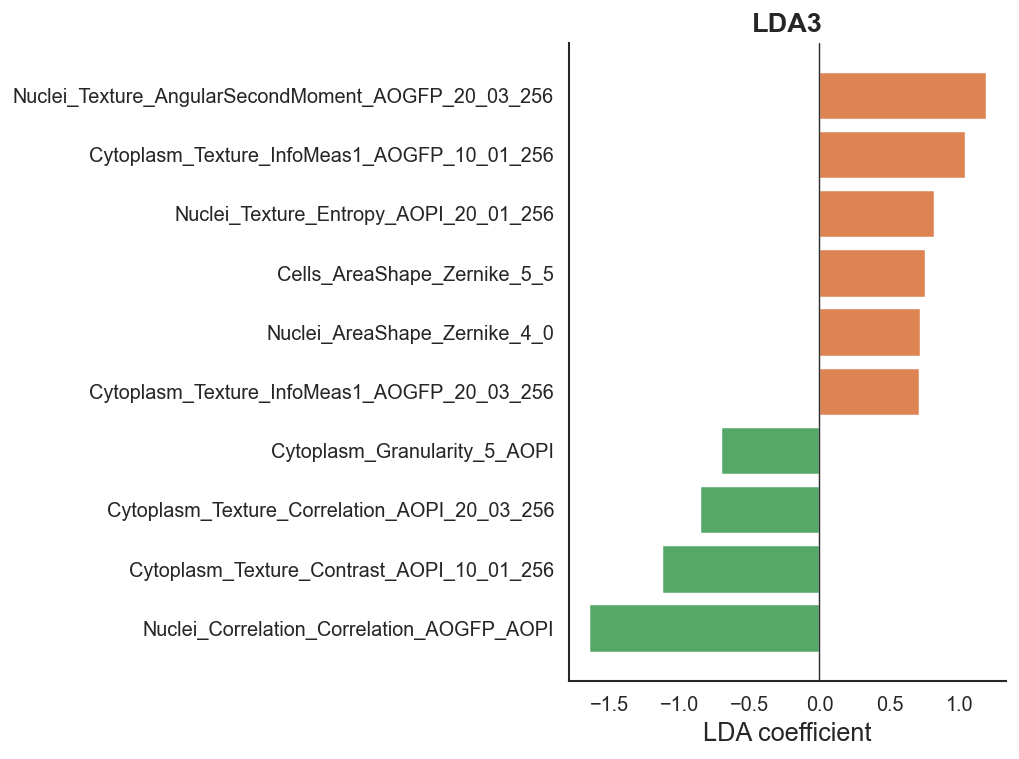

In [21]:
if lda_loadings is None:
    print("Skipped: valid LDA loadings were not available.")
else:
    for axis in lda_columns[:3]:
        selected_features = (
            lda_loadings[axis]
            .abs()
            .nlargest(10)
            .index
        )
        selected_values = (
            lda_loadings
            .loc[selected_features, axis]
            .sort_values()
        )

        fig, ax = plt.subplots(figsize=(8, 6))
        colors = [
            LDA_COLOR if value >= 0 else "#55A868"
            for value in selected_values.values
        ]
        ax.barh(
            selected_values.index,
            selected_values.values,
            color=colors,
        )
        ax.axvline(
            0,
            color=THRESHOLD_COLOR,
            linewidth=0.8,
        )
        ax.set_xlabel("LDA coefficient")
        ax.set_ylabel("")
        ax.set_title(axis)
        sns.despine()
        save_figure(
            f"Top_LDA_features_{axis}.png",
            OUTPUT_DIR,
        )

    lda_loadings.to_csv(
        OUTPUT_DIR / "LDA_feature_coefficients.csv"
    )

## 12. Reproducibility across independent plates

For each condition, technical wells are first aggregated within plate. Pearson correlations are then calculated only between profiles from different plates. The empirical null distribution consists of different-condition pairs from different plates. Its 95th percentile is used as the reproducibility threshold.

Conditions represented on only one plate are classified as **Not evaluable**, not as non-reproducible.


### Well-level Percent Replicating and G0 reference-control QC

Percent Replicating is calculated from **well-level profiles**. Replicate pairs must represent the same condition on different plates, while the empirical null distribution is generated from random non-matching well pairs on different plates. The 95th percentile of the null distribution is used as the reproducibility threshold.

`G0-arrested (DMSO)` is the plate-wise normalization reference. Its normalized profile is centred on zero by design, so correlation-based PR is not interpreted for G0 and the reference is excluded from the null distribution and PR denominator. G0 quality is instead evaluated using distance-based metrics that remain meaningful after normalization: the distance of each well from its plate median and the distance of the plate-median profile from zero.


In [14]:
# ---------------------------------------------------------------------
# WELL-LEVEL PERCENT REPLICATING
# ---------------------------------------------------------------------
# This implementation uses well-level profiles rather than collapsing each
# condition to one median profile per plate. Same-condition pairs are restricted
# to different plates so that technical wells on the same plate are not counted
# as independent replication.

pr_features = [
    column
    for column in feature_columns
    if analysis_df[column].nunique(dropna=True) > 1
]

if len(pr_features) < 2:
    raise ValueError(
        "Fewer than two variable features were available for PR analysis."
    )

pr_records = (
    analysis_df[
        [CONDITION_COL, PLATE_COL, WELL_COL, *pr_features]
    ]
    .dropna(subset=[CONDITION_COL, PLATE_COL])
    .reset_index(drop=True)
    .copy()
)

# Correlation helper that returns NaN for constant/invalid profiles.
def profile_correlation(profile_a, profile_b):
    profile_a = pd.Series(profile_a, dtype=float)
    profile_b = pd.Series(profile_b, dtype=float)

    valid = profile_a.notna() & profile_b.notna()
    if valid.sum() < 2:
        return np.nan

    a = profile_a.loc[valid]
    b = profile_b.loc[valid]

    if a.nunique() < 2 or b.nunique() < 2:
        return np.nan

    if PR_CORRELATION_METHOD.lower() == "spearman":
        return float(a.corr(b, method="spearman"))

    return float(a.corr(b, method="pearson"))


# ---------------------------------------------------------------------
# 1. Same-condition replicate correlations across independent plates
# ---------------------------------------------------------------------
same_condition_rows = []

for condition, condition_table in pr_records.groupby(
    CONDITION_COL,
    observed=True,
):
    if condition == REFERENCE_CONTROL:
        continue

    condition_table = condition_table.reset_index(drop=True)

    for i, j in combinations(range(len(condition_table)), 2):
        plate_i = condition_table.loc[i, PLATE_COL]
        plate_j = condition_table.loc[j, PLATE_COL]

        if plate_i == plate_j:
            continue

        correlation = profile_correlation(
            condition_table.loc[i, pr_features],
            condition_table.loc[j, pr_features],
        )

        if not np.isfinite(correlation):
            continue

        same_condition_rows.append({
            "Condition": condition,
            "Correlation": correlation,
            "Plate_1": plate_i,
            "Plate_2": plate_j,
            "Well_1": (
                condition_table.loc[i, WELL_COL]
                if WELL_COL is not None
                else i
            ),
            "Well_2": (
                condition_table.loc[j, WELL_COL]
                if WELL_COL is not None
                else j
            ),
        })

same_condition_df = pd.DataFrame(same_condition_rows)


# ---------------------------------------------------------------------
# 2. Empirical null from random non-matching wells on different plates
# ---------------------------------------------------------------------
null_pool = (
    pr_records.loc[
        pr_records[CONDITION_COL] != REFERENCE_CONTROL
    ]
    .reset_index(drop=True)
)

eligible_null_pairs = []

for i, j in combinations(range(len(null_pool)), 2):
    if (
        null_pool.loc[i, PLATE_COL] == null_pool.loc[j, PLATE_COL]
        or null_pool.loc[i, CONDITION_COL] == null_pool.loc[j, CONDITION_COL]
    ):
        continue
    eligible_null_pairs.append((i, j))

if not eligible_null_pairs:
    raise ValueError(
        "No valid non-matching cross-plate pairs were available "
        "for the empirical null distribution."
    )

rng = np.random.default_rng(PR_RANDOM_STATE)

if len(eligible_null_pairs) > NULL_PAIR_SAMPLE_SIZE:
    selected_pair_indices = rng.choice(
        len(eligible_null_pairs),
        size=NULL_PAIR_SAMPLE_SIZE,
        replace=False,
    )
    selected_null_pairs = [
        eligible_null_pairs[index]
        for index in selected_pair_indices
    ]
else:
    selected_null_pairs = eligible_null_pairs

null_rows = []

for i, j in selected_null_pairs:
    correlation = profile_correlation(
        null_pool.loc[i, pr_features],
        null_pool.loc[j, pr_features],
    )

    if not np.isfinite(correlation):
        continue

    null_rows.append({
        "Correlation": correlation,
        "Condition_1": null_pool.loc[i, CONDITION_COL],
        "Condition_2": null_pool.loc[j, CONDITION_COL],
        "Plate_1": null_pool.loc[i, PLATE_COL],
        "Plate_2": null_pool.loc[j, PLATE_COL],
        "Well_1": (
            null_pool.loc[i, WELL_COL]
            if WELL_COL is not None
            else i
        ),
        "Well_2": (
            null_pool.loc[j, WELL_COL]
            if WELL_COL is not None
            else j
        ),
    })

null_df = pd.DataFrame(null_rows)

if null_df.empty:
    raise ValueError(
        "The empirical null distribution contained no finite correlations."
    )

null_threshold = float(
    null_df["Correlation"].quantile(0.95)
)


# ---------------------------------------------------------------------
# 3. Condition-level PR classification
# ---------------------------------------------------------------------
reproducibility_rows = []

for condition, group in pr_records.groupby(
    CONDITION_COL,
    observed=True,
):
    independent_plates = int(group[PLATE_COL].nunique())
    total_wells = int(len(group))

    if condition == REFERENCE_CONTROL:
        condition_correlations = pd.Series(dtype=float)
        median_correlation = np.nan
        status = "Reference control"
    else:
        condition_correlations = (
            same_condition_df.loc[
                same_condition_df["Condition"] == condition,
                "Correlation",
            ]
            if not same_condition_df.empty
            else pd.Series(dtype=float)
        )

        median_correlation = (
            float(condition_correlations.median())
            if not condition_correlations.empty
            else np.nan
        )

        if independent_plates < 2 or condition_correlations.empty:
            status = "Not evaluable"
        elif median_correlation >= null_threshold:
            status = "Reproducible"
        else:
            status = "Not reproducible"

    reproducibility_rows.append({
        "Condition": condition,
        "Independent plates": independent_plates,
        "Total wells": total_wells,
        "Number of cross-plate replicate pairs": int(
            len(condition_correlations)
        ),
        "Median replicate correlation": median_correlation,
        "Null threshold": null_threshold,
        "Reproducibility status": status,
    })

reproducibility_table = pd.DataFrame(reproducibility_rows)

evaluable_table = reproducibility_table.loc[
    reproducibility_table["Reproducibility status"].isin([
        "Reproducible",
        "Not reproducible",
    ])
].copy()

percent_replicating = (
    100
    * evaluable_table["Reproducibility status"]
    .eq("Reproducible")
    .mean()
    if not evaluable_table.empty
    else np.nan
)

print(
    f"Well-level PR correlation: {PR_CORRELATION_METHOD}"
)
print(
    f"Empirical null pairs: {len(null_df):,}"
)
print(
    f"Null threshold (95th percentile): {null_threshold:.3f}"
)
print(
    f"Evaluable treatment conditions: {len(evaluable_table)} "
    f"of {len(reproducibility_table)} total conditions"
)
print(
    f"{REFERENCE_CONTROL}: evaluated separately as the normalization reference."
)

if np.isfinite(percent_replicating):
    print(f"Percent replicating: {percent_replicating:.1f}%")
else:
    print("Percent replicating: not evaluable")

display(
    reproducibility_table.sort_values(
        ["Reproducibility status", "Median replicate correlation"],
        ascending=[True, False],
        na_position="last",
    )
)


# ---------------------------------------------------------------------
# 4. G0 REFERENCE-CONTROL QC
# ---------------------------------------------------------------------
# Correlation is not used here because the reference was centred on zero
# during plate-wise normalization. Distance-based metrics remain interpretable.

g0_records = pr_records.loc[
    pr_records[CONDITION_COL] == REFERENCE_CONTROL
].copy()

g0_qc_rows = []
g0_well_distance_rows = []

for plate, plate_table in g0_records.groupby(
    PLATE_COL,
    observed=True,
):
    plate_table = plate_table.reset_index(drop=True)
    feature_matrix = plate_table[pr_features].astype(float)

    plate_median = feature_matrix.median(axis=0)

    # Root-mean-square distance across all retained features.
    per_well_distance_to_zero = np.sqrt(
        np.square(feature_matrix).mean(axis=1)
    )
    per_well_distance_to_plate_median = np.sqrt(
        np.square(feature_matrix - plate_median).mean(axis=1)
    )

    for row_index in range(len(plate_table)):
        g0_well_distance_rows.append({
            "Plate": plate,
            "Well": (
                plate_table.loc[row_index, WELL_COL]
                if WELL_COL is not None
                else row_index
            ),
            "RMS distance from zero": float(
                per_well_distance_to_zero.iloc[row_index]
            ),
            "RMS distance from plate median": float(
                per_well_distance_to_plate_median.iloc[row_index]
            ),
        })

    g0_qc_rows.append({
        "Plate": plate,
        "Number of G0 wells": int(len(plate_table)),
        "Median absolute plate profile": float(
            plate_median.abs().median()
        ),
        "RMS plate-profile distance from zero": float(
            np.sqrt(np.square(plate_median).mean())
        ),
        "Median well RMS distance from zero": float(
            per_well_distance_to_zero.median()
        ),
        "Median well RMS distance from plate median": float(
            per_well_distance_to_plate_median.median()
        ),
        "Maximum well RMS distance from plate median": float(
            per_well_distance_to_plate_median.max()
        ),
    })

g0_qc_table = pd.DataFrame(g0_qc_rows)
g0_well_distances = pd.DataFrame(g0_well_distance_rows)

print("\nG0 normalization-reference QC:")
display(
    g0_qc_table.sort_values(
        "Median well RMS distance from plate median",
        ascending=True,
    )
)


Well-level PR correlation: pearson
Empirical null pairs: 10,000
Null threshold (95th percentile): 0.362
Evaluable treatment conditions: 30 of 37 total conditions
G0-arrested (DMSO): evaluated separately as the normalization reference.
Percent replicating: 16.7%


,Condition,Independent plates,Total wells,Number of cross-plate replicate pairs,Median replicate correlation,Null threshold,Reproducibility status
4,CP21R7,1,4,0,NaN,0.362296,Not evaluable
5,CaffeicAcid,1,4,0,NaN,0.362296,Not evaluable
8,Chloroquine,1,4,0,NaN,0.362296,Not evaluable
9,Escitalopram,1,4,0,NaN,0.362296,Not evaluable
25,Proliferative,1,4,0,NaN,0.362296,Not evaluable
32,Sitagliptin,1,4,0,NaN,0.362296,Not evaluable
2,Artesunate,2,7,12,0.237579,0.362296,Not reproducible
26,Propanolol,2,8,16,0.235408,0.362296,Not reproducible
11,FenofibricAcid,2,8,16,0.205424,0.362296,Not reproducible
27,Rapamycin,2,8,16,0.159622,0.362296,Not reproducible



G0 normalization-reference QC:


,Plate,Number of G0 wells,Median absolute plate profile,RMS plate-profile distance from zero,Median well RMS distance from zero,Median well RMS distance from plate median,Maximum well RMS distance from plate median
5,240806_171324_Plate_1_,11,0.080052,1.371793e-01,1.157661,1.140850,6.396391
0,240801_122543_Plate_1_,12,0.000000,1.062623e-14,1.189418,1.189418,15.116257
4,240806_145111_Plate_1_,12,0.000000,3.384069e-15,1.192346,1.192346,2.318028
1,240801_144209_Plate_1_,7,0.000000,0.000000e+00,1.245767,1.245767,2.024633
2,240801_165802_Plate_1_,11,0.000000,0.000000e+00,1.258639,1.258639,3.621736
3,240806_124138_Plate_1_,8,0.000000,3.618059e-15,1.381962,1.381962,2.042913


## 13. Reproducibility figures

The empirical null distribution is shown in grey, with subtle reference lines for all evaluable conditions and coloured lines only for conditions exceeding the reproducibility threshold. Condition-level results are presented as a Cleveland dot plot without horizontal stems, since no confidence intervals are being displayed. Classification counts use a softer publication palette.

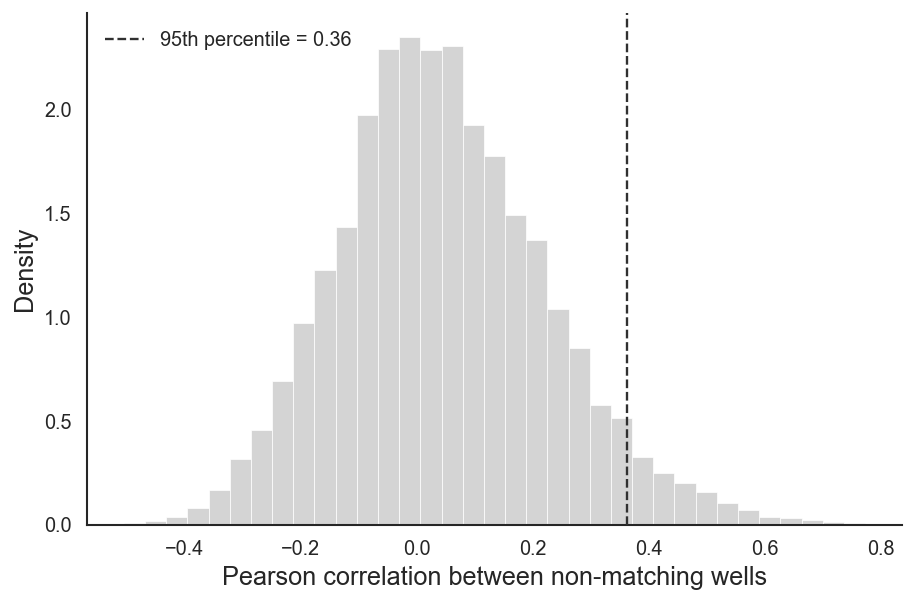

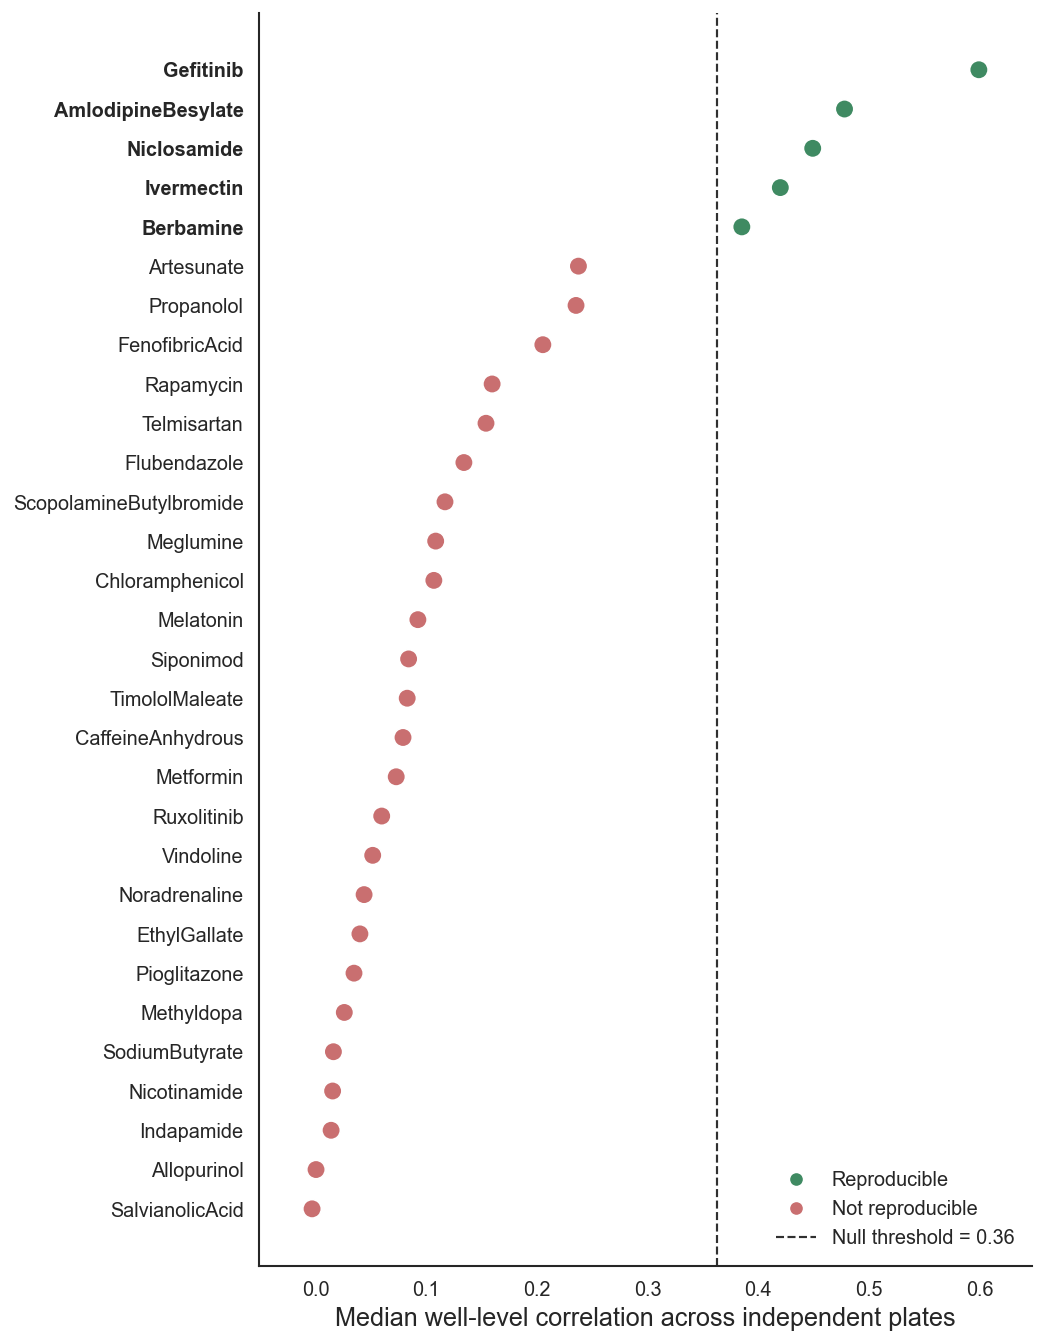

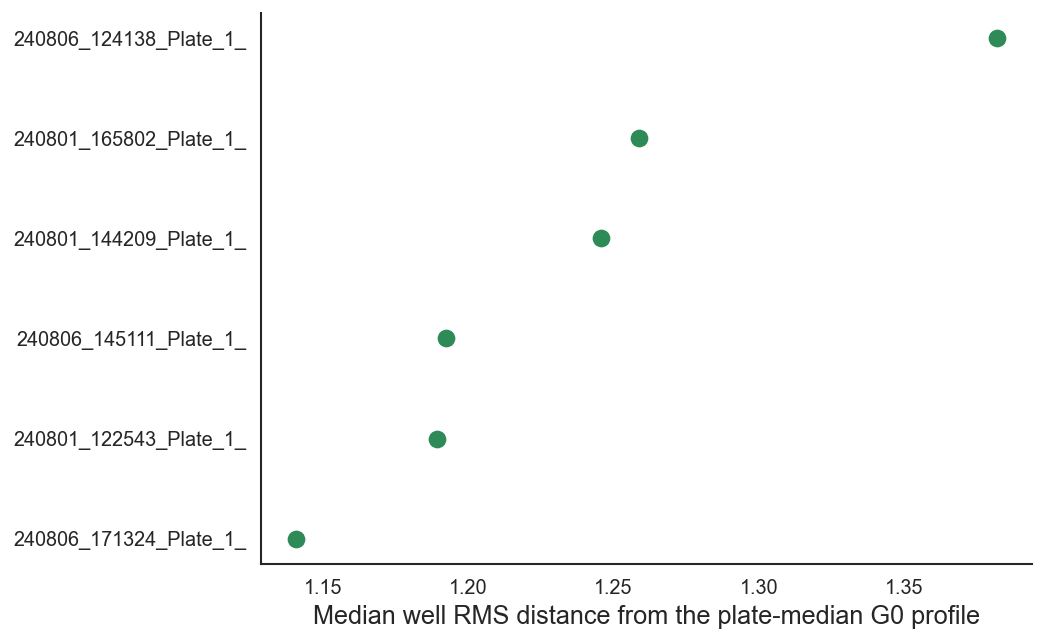

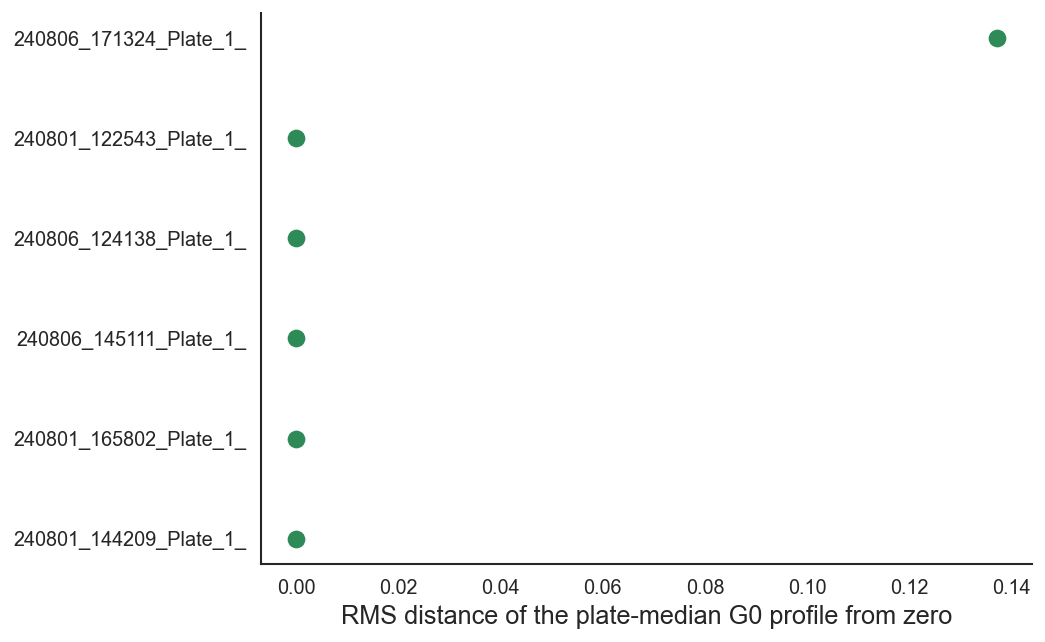

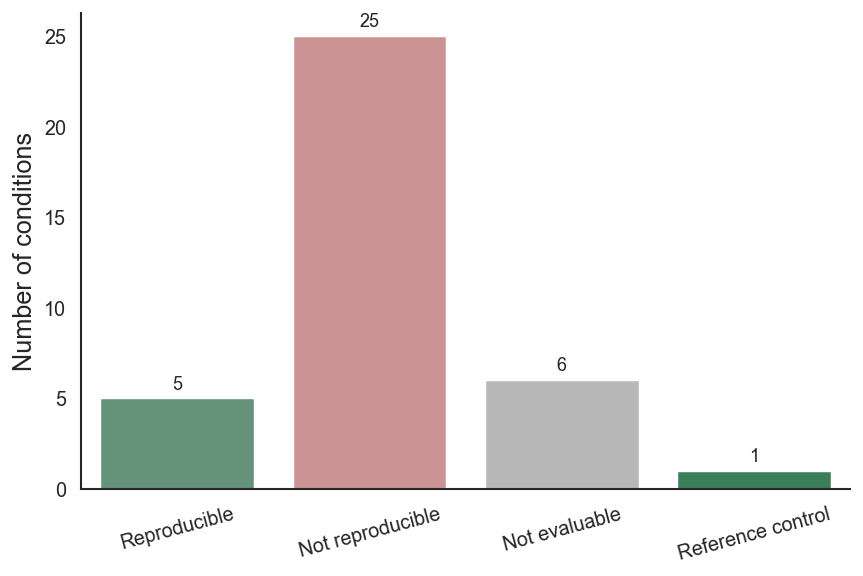

In [15]:
# Final publication-oriented reproducibility figures

# ---------------------------------------------------------------------
# 1. Empirical null distribution
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.2, 4.8))

sns.histplot(
    null_df["Correlation"],
    bins=35,
    stat="density",
    color="#C9C9C9",
    alpha=0.78,
    edgecolor="white",
    linewidth=0.4,
    ax=ax,
)

ax.axvline(
    null_threshold,
    color=THRESHOLD_COLOR,
    linestyle="--",
    linewidth=1.3,
    label=f"95th percentile = {null_threshold:.2f}",
    zorder=4,
)

ax.set_xlabel(
    f"{PR_CORRELATION_METHOD.capitalize()} correlation "
    "between non-matching wells"
)
ax.set_ylabel("Density")
ax.legend(frameon=False, loc="upper left")
sns.despine()

save_figure(
    "Percent_replicating_null_distribution.png",
    OUTPUT_DIR,
)


# ---------------------------------------------------------------------
# 2. Condition-level PR plot
# ---------------------------------------------------------------------
plot_table = (
    reproducibility_table
    .loc[
        reproducibility_table["Reproducibility status"].isin([
            "Reproducible",
            "Not reproducible",
        ])
    ]
    .dropna(subset=["Median replicate correlation"])
    .sort_values(
        "Median replicate correlation",
        ascending=True,
    )
    .copy()
)

status_palette = {
    "Reproducible": "#3F8A62",
    "Not reproducible": "#C96F70",
}

if plot_table.empty:
    print(
        "Condition-level PR plot skipped: no condition was evaluable."
    )
else:
    figure_height = max(
        5.5,
        0.30 * len(plot_table) + 1.5,
    )

    fig, ax = plt.subplots(
        figsize=(8.2, figure_height)
    )

    y_positions = np.arange(len(plot_table))

    point_colors = [
        status_palette[status]
        for status in plot_table[
            "Reproducibility status"
        ]
    ]

    ax.scatter(
        plot_table["Median replicate correlation"],
        y_positions,
        c=point_colors,
        marker="o",
        s=105,
        edgecolor="white",
        linewidth=0.9,
        zorder=3,
    )

    ax.axvline(
        null_threshold,
        color=THRESHOLD_COLOR,
        linestyle="--",
        linewidth=1.2,
        zorder=2,
    )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(plot_table["Condition"])
    ax.set_xlabel(
        "Median well-level correlation across independent plates"
    )
    ax.set_ylabel("")

    reproducible_conditions = set(
        plot_table.loc[
            plot_table["Reproducibility status"] == "Reproducible",
            "Condition",
        ]
    )

    for tick_label in ax.get_yticklabels():
        if tick_label.get_text() in reproducible_conditions:
            tick_label.set_fontweight("bold")

    x_min = min(
        plot_table["Median replicate correlation"].min(),
        null_threshold,
    )
    x_max = max(
        plot_table["Median replicate correlation"].max(),
        null_threshold,
    )
    x_padding = max(0.04, 0.08 * (x_max - x_min))
    ax.set_xlim(x_min - x_padding, x_max + x_padding)

    legend_handles = [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markerfacecolor=status_palette["Reproducible"],
            markeredgecolor="white",
            markersize=8,
            label="Reproducible",
        ),
        plt.Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markerfacecolor=status_palette["Not reproducible"],
            markeredgecolor="white",
            markersize=8,
            label="Not reproducible",
        ),
        plt.Line2D(
            [0],
            [0],
            color=THRESHOLD_COLOR,
            linestyle="--",
            linewidth=1.2,
            label=f"Null threshold = {null_threshold:.2f}",
        ),
    ]

    ax.legend(
        handles=legend_handles,
        frameon=False,
        loc="lower right",
    )

    sns.despine()

    save_figure(
        "Replicate_correlation_by_condition.png",
        OUTPUT_DIR,
    )


# ---------------------------------------------------------------------
# 3. G0 QC: dispersion around the plate median
# ---------------------------------------------------------------------
if g0_qc_table.empty:
    print("G0 QC plot skipped: no reference-control wells were found.")
else:
    g0_dispersion_plot = g0_qc_table.sort_values(
        "Median well RMS distance from plate median",
        ascending=True,
    ).copy()

    fig, ax = plt.subplots(
        figsize=(8.2, max(4.8, 0.55 * len(g0_dispersion_plot) + 1.8))
    )

    y_positions = np.arange(len(g0_dispersion_plot))

    ax.scatter(
        g0_dispersion_plot[
            "Median well RMS distance from plate median"
        ],
        y_positions,
        s=115,
        color=G0_COLOR,
        edgecolor="white",
        linewidth=0.9,
        zorder=3,
    )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(g0_dispersion_plot["Plate"])
    ax.set_xlabel(
        "Median well RMS distance from the plate-median G0 profile"
    )
    ax.set_ylabel("")
    sns.despine()

    save_figure(
        "G0_reference_control_dispersion_around_plate_median.png",
        OUTPUT_DIR,
    )


# ---------------------------------------------------------------------
# 4. G0 QC: plate-median distance from normalized zero
# ---------------------------------------------------------------------
if not g0_qc_table.empty:
    g0_zero_plot = g0_qc_table.sort_values(
        "RMS plate-profile distance from zero",
        ascending=True,
    ).copy()

    fig, ax = plt.subplots(
        figsize=(8.2, max(4.8, 0.55 * len(g0_zero_plot) + 1.8))
    )

    y_positions = np.arange(len(g0_zero_plot))

    ax.scatter(
        g0_zero_plot[
            "RMS plate-profile distance from zero"
        ],
        y_positions,
        s=115,
        color=G0_COLOR,
        edgecolor="white",
        linewidth=0.9,
        zorder=3,
    )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(g0_zero_plot["Plate"])
    ax.set_xlabel(
        "RMS distance of the plate-median G0 profile from zero"
    )
    ax.set_ylabel("")
    sns.despine()

    save_figure(
        "G0_reference_control_distance_from_zero.png",
        OUTPUT_DIR,
    )


# ---------------------------------------------------------------------
# 5. Summary of PR classifications
# ---------------------------------------------------------------------
status_order = [
    "Reproducible",
    "Not reproducible",
    "Not evaluable",
    "Reference control",
]

summary_palette = {
    "Reproducible": "#5D9B78",
    "Not reproducible": "#D58A8B",
    "Not evaluable": "#B8B8B8",
    "Reference control": G0_COLOR,
}

status_counts = (
    reproducibility_table[
        "Reproducibility status"
    ]
    .value_counts()
    .reindex(status_order, fill_value=0)
    .rename_axis("Status")
    .reset_index(name="Number of conditions")
)

fig, ax = plt.subplots(figsize=(6.8, 4.6))

sns.barplot(
    data=status_counts,
    x="Status",
    y="Number of conditions",
    hue="Status",
    palette=summary_palette,
    legend=False,
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3,
        fontsize=10,
    )

ax.set_xlabel("")
ax.set_ylabel("Number of conditions")
ax.tick_params(axis="x", rotation=15)
sns.despine()

save_figure(
    "Reproducibility_status_summary.png",
    OUTPUT_DIR,
)


# ---------------------------------------------------------------------
# 6. Export PR and G0 QC tables
# ---------------------------------------------------------------------
same_condition_df.to_csv(
    OUTPUT_DIR
    / "Same_condition_well_correlations_across_plates.csv",
    index=False,
)

null_df.to_csv(
    OUTPUT_DIR
    / "Different_condition_well_null_correlations.csv",
    index=False,
)

reproducibility_table.to_csv(
    OUTPUT_DIR
    / "Percent_replicating_by_condition.csv",
    index=False,
)

status_counts.to_csv(
    OUTPUT_DIR
    / "Reproducibility_status_counts.csv",
    index=False,
)

g0_qc_table.to_csv(
    OUTPUT_DIR
    / "G0_reference_control_QC_by_plate.csv",
    index=False,
)

g0_well_distances.to_csv(
    OUTPUT_DIR
    / "G0_well_distance_diagnostics.csv",
    index=False,
)

## 14. Conditions not evaluable between plates

In [16]:
single_plate_report = (
    well_audit
    .groupby(CONDITION_COL, observed=True)
    .agg(
        Independent_plates=(
            PLATE_COL,
            "nunique",
        ),
        Total_remaining_wells=(
            "Number_of_wells",
            "sum",
        ),
    )
    .query("Independent_plates < 2")
    .sort_index()
)

display(single_plate_report)

single_plate_report.to_csv(
    OUTPUT_DIR
    / "Conditions_not_evaluable_between_plates.csv"
)

,Independent_plates,Total_remaining_wells
Metadata_compound,,
CP21R7,1,4
CaffeicAcid,1,4
Chloroquine,1,4
Escitalopram,1,4
Proliferative,1,4
Sitagliptin,1,4


## 15. Optional pathway annotation

The pathway table must contain `Metadata_compound` and `Metadata_Pathway`. Cluster assignments are taken from `pca_cluster_df`, avoiding the earlier undefined `Cluster` column in `pca_df`.


In [17]:
if PATHWAY_PATH is None:
    print(
        "Skipped: PATHWAY_PATH was not provided."
    )
else:
    pathway_path = Path(PATHWAY_PATH)

    if not pathway_path.exists():
        print(
            "Skipped: pathway file was not found at "
            f"{pathway_path.resolve()}."
        )
    else:
        pathway_df = pd.read_csv(
            pathway_path
        )

        required_columns = {
            "Metadata_compound",
            "Metadata_Pathway",
        }

        if not required_columns.issubset(
            pathway_df.columns
        ):
            print(
                "Skipped: pathway table must contain "
                f"{sorted(required_columns)}."
            )
        else:
            cluster_annotation = (
                pca_cluster_df[
                    [CONDITION_COL, "Cluster"]
                ]
                .drop_duplicates()
                .merge(
                    pathway_df[
                        [
                            "Metadata_compound",
                            "Metadata_Pathway",
                        ]
                    ].drop_duplicates(),
                    left_on=CONDITION_COL,
                    right_on="Metadata_compound",
                    how="left",
                )
                .drop(
                    columns="Metadata_compound"
                )
            )

            display(cluster_annotation)

            cluster_annotation.to_csv(
                OUTPUT_DIR
                / "Cluster_pathway_annotation.csv",
                index=False,
            )

Skipped: PATHWAY_PATH was not provided.


## 16. Final output manifest

This cell lists every file generated during the executed analysis.


In [18]:
output_files = sorted(
    path.name
    for path in OUTPUT_DIR.glob("*")
    if path.is_file()
)

print(
    f"{len(output_files)} output files in "
    f"{OUTPUT_DIR.resolve()}"
)
display(
    pd.DataFrame({
        "Output file": output_files
    })
)

49 output files in /Users/thaismlacerda/Library/CloudStorage/GoogleDrive-thaismllacerda@gmail.com/Meu Drive/Doutorado Thais/Github_Analysis/Drugalone_validation_dormant/Analysis/publication_outputs


,Output file
0,Conditions_not_evaluable_between_plates.csv
1,Different_condition_well_null_correlations.csv
2,G0_isolated_point_diagnostic.csv
3,G0_point_excluded_from_3D.csv
4,G0_reference_control_QC_by_plate.csv
5,G0_reference_control_dispersion_around_plate_m...
6,G0_reference_control_distance_from_zero.png
7,G0_well_distance_diagnostics.csv
8,Kmeans_cluster_composition_and_labels.csv
9,Kmeans_clusters_LDA.png
